# Task 1 — Data Preparation and Feature Engineering



## Task 1.1 — Ticker Selection and Data Acquisition

In [1]:
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

start, end = "2021-01-01", "2025-01-01"  # The end date is exclusive.
# Leave this False when reproducing the report.
COLLECT_NEW_SNAPSHOT = False
RAW_BASE = (
    "https://raw.githubusercontent.com/azeem20242155-byte/"
    "6BUIS017W-CRM-CM/df93fcd20c3d3854eb2ed0626639787eb550976e/"
)

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| numpy:", np.__version__)
print("Original snapshot downloaded with yfinance 0.2.66.")

Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6
Original snapshot downloaded with yfinance 0.2.66.


### Read the saved data from the local folder or GitHub

In [2]:
#Load the three Task 1 data files { display-mode: "form" }
ticker_file = "sp500_ticker_list.csv"
benchmark_file = "sp500_benchmark_daily.csv"
shares_file = "sp500_shares_daily_raw.csv.gz"

def read_saved_data():
    # Use one source for the complete set, not a mix of local and remote files.
    local_shares = Path(shares_file)
    if not local_shares.exists():
        local_shares = Path("sp500_shares_daily_raw.csv")
    if all(path.is_file() for path in [Path(ticker_file), Path(benchmark_file), local_shares]):
        paths = [ticker_file, benchmark_file, str(local_shares)]
        source = "Local saved snapshot"
    else:
        paths = [RAW_BASE + name for name in [ticker_file, benchmark_file, shares_file]]
        source = "GitHub saved snapshot (pinned commit)"

    try:
        tickers = pd.read_csv(paths[0])
        index = pd.read_csv(paths[1], index_col=0, parse_dates=True,
                            float_precision="round_trip")
        shares = pd.read_csv(paths[2], header=[0, 1], index_col=0, parse_dates=True,
                             float_precision="round_trip",
                             compression="gzip" if paths[2].endswith(".gz") else None)
    except Exception as error:
        raise RuntimeError(f"Could not read the three inputs from {source}: {error}") from error
    print("Data source:", source)
    return tickers, index, shares

def collect_new_snapshot():
    # Only used for a new data collection. Install yfinance and lxml first.
    import yfinance as yf

    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    columns = ["Symbol", "Security", "GICS Sector"]
    tickers = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})[0][columns].copy()
    tickers["Yahoo_Ticker"] = tickers["Symbol"].str.replace(".", "-", regex=False)
    tickers["Retrieval_Date_UTC"] = datetime.now(timezone.utc).date().isoformat()
    index = yf.download("^GSPC", start=start, end=end, interval="1d",
                        auto_adjust=False, multi_level_index=False)
    shares = yf.download(tickers["Yahoo_Ticker"].tolist(), start=start, end=end,
                         interval="1d", auto_adjust=False, actions=True, group_by="ticker",
                         multi_level_index=True)
    if index.empty or shares.empty or index["Adj Close"].isna().all():
        raise RuntimeError("Yahoo Finance returned no usable benchmark or share data.")

    # Keep the new download separate so it cannot overwrite the report data.
    folder = Path("new_snapshot")
    folder.mkdir(exist_ok=True)
    tickers.to_csv(folder / ticker_file, index=False)
    index.to_csv(folder / benchmark_file, index_label="Date")
    shares.to_csv(folder / shares_file, index_label="Date", compression="gzip")
    print("Data source: new Wikipedia and Yahoo Finance download | yfinance:", yf.__version__)
    return tickers, index, shares

if COLLECT_NEW_SNAPSHOT:
    try:
        ticker_list, benchmark, shares_daily = collect_new_snapshot()
    except Exception as error:
        print(f"New download failed ({error}). Using the saved snapshot.")
        ticker_list, benchmark, shares_daily = read_saved_data()
else:
    ticker_list, benchmark, shares_daily = read_saved_data()

Data source: GitHub saved snapshot (pinned commit)


In [3]:
tickers = ticker_list["Yahoo_Ticker"].tolist()
assert ticker_list["Yahoo_Ticker"].is_unique
returned = set(shares_daily.columns.get_level_values(0))
with_close = [
    ticker for ticker in tickers
    if ticker in returned and "Close" in shares_daily[ticker].columns
    and shares_daily[ticker]["Close"].notna().any()
]
no_close = sorted(set(tickers) - set(with_close))

print("Ticker list retrieval date (UTC):", ticker_list["Retrieval_Date_UTC"].iloc[0])
print("Candidate tickers:", len(tickers))
print("With closing prices:", len(with_close))
print("No closing prices returned:", no_close)
print("Benchmark dates:", benchmark.index.min().date(), "to",
      benchmark.index.max().date(), "| Rows:", len(benchmark))
display(ticker_list.head())

Ticker list retrieval date (UTC): 2026-11-19
Candidate tickers: 503
With closing prices: 498
No closing prices returned: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Benchmark dates: 2021-01-04 to 2024-12-31 | Rows: 1005


,Symbol,Security,GICS Sector,Yahoo_Ticker,Retrieval_Date_UTC
0,MMM,3M,Industrials,MMM,2026-11-19
1,AOS,A. O. Smith,Industrials,AOS,2026-11-19
2,ABT,Abbott Laboratories,Health Care,ABT,2026-11-19
3,ABBV,AbbVie,Health Care,ABBV,2026-11-19
4,ACN,Accenture,Information Technology,ACN,2026-11-19


 Adjusted Close was used for returns to account for splits and distributions. Monetary uses Close × Volume as specified.

The constituent list was retrieved in November 2026 and applied to the January 2021–December 2024 data. Shares that left the index and did not return by retrieval may be missing. Later additions can enter the analysis only if they pass the coverage checks. Five tickers returned no prices for the period

## Task 1.2 — Data Validation and Alignment

### Daily coverage

In [4]:
# Check the date labels for duplications.
print("Duplicate dates in benchmark:", benchmark.index.duplicated().sum())
print("Duplicate dates in share data:", shares_daily.index.duplicated().sum())

if benchmark.index.has_duplicates or shares_daily.index.has_duplicates:
    raise ValueError("Inspect the duplicate dates before continuing.")

# Used the benchmark trading dates without filling missing prices.
expected_dates = benchmark.index.sort_values()
returned = set(shares_daily.columns.get_level_values(0))
coverage_rows = []

for ticker in tickers:
    if ticker in returned and "Close" in shares_daily[ticker].columns:
        close = shares_daily[ticker]["Close"].reindex(expected_dates)
    else:
        close = pd.Series(index=expected_dates, dtype=float)

    observed = close.dropna()

    coverage_rows.append({
        "Ticker": ticker,
        "First_close": observed.index.min(),
        "Last_close": observed.index.max(),
        "Closing_prices": len(observed),
        "Missing_closes": len(expected_dates) - len(observed)
    })

coverage = pd.DataFrame(coverage_rows)

print("Benchmark trading dates:", len(expected_dates))
print("Tickers with a close on every benchmark date:",
      coverage["Missing_closes"].eq(0).sum())
print("Tickers with some, but not all, closing prices:",
      (coverage["Closing_prices"].gt(0) &
       coverage["Missing_closes"].gt(0)).sum())
print("Tickers with no closing prices:",
      coverage["Closing_prices"].eq(0).sum())

display(coverage.sort_values("Missing_closes", ascending=False).head(10))

Duplicate dates in benchmark: 0
Duplicate dates in share data: 0
Benchmark trading dates: 1005
Tickers with a close on every benchmark date: 488
Tickers with some, but not all, closing prices: 10
Tickers with no closing prices: 5


,Ticker,First_close,Last_close,Closing_prices,Missing_closes
233,HONA,NaT,NaT,0,1005
192,FDXF,NaT,NaT,0,1005
379,Q,NaT,NaT,0,1005
402,SNDK,NaT,NaT,0,1005
478,VYLR,NaT,NaT,0,1005
211,GEV,2024-03-27,2024-12-31,193,812
415,SOLV,2024-03-26,2024-12-31,194,811
385,RDDT,2024-03-21,2024-12-31,197,808
466,VLTO,2023-10-04,2024-12-31,313,692
210,GEHC,2022-12-15,2024-12-31,513,492


### Prices, volume and corporate actions

In [5]:
def check_values(series, is_price):
    values = pd.to_numeric(series, errors="coerce")
    invalid = series.notna() & ~np.isfinite(values)

    # Prices must be positive. Volume cannot be negative.
    invalid |= values.le(0) if is_price else values.lt(0)

    return int(series.isna().sum()), int(invalid.sum())

quality_rows = []

for ticker in with_close:
    daily = shares_daily[ticker].reindex(expected_dates)
    row = {"Ticker": ticker}

    for field in ["Close", "Adj Close", "Volume"]:
        series = daily.get(field, pd.Series(np.nan, index=expected_dates))
        missing, invalid = check_values(series, is_price=(field != "Volume"))
        row[f"Missing {field}"] = missing
        row[f"Invalid {field}"] = invalid

    # Counted reported events. A split or dividend is not a data error.
    for field in ["Stock Splits", "Dividends"]:
        if field in daily and daily[field].notna().any():
            row[field] = int((daily[field].notna() & daily[field].ne(0)).sum())
        else:
            row[field] = pd.NA

    quality_rows.append(row)

quality = pd.DataFrame(quality_rows)

print("Shares with at least one missing value, by field")
print(quality.filter(like="Missing ").gt(0).sum())

print("\nShares with at least one invalid value, by field")
print(quality.filter(like="Invalid ").gt(0).sum())

print("\nShares with at least one reported corporate action")
print(quality[["Stock Splits", "Dividends"]].fillna(0).gt(0).sum())

print("\nBenchmark Adj Close (missing, invalid):",
      check_values(benchmark["Adj Close"], is_price=True))

Shares with at least one missing value, by field
Missing Close        10
Missing Adj Close    10
Missing Volume       10
dtype: int64

Shares with at least one invalid value, by field
Invalid Close        0
Invalid Adj Close    0
Invalid Volume       0
dtype: int64

Shares with at least one reported corporate action
Stock Splits     53
Dividends       399
dtype: int64

Benchmark Adj Close (missing, invalid): (0, 0)


In [6]:
# Review invalid values before they enter the feature calculations.
if quality.filter(like="Invalid ").gt(0).any().any():
    raise ValueError("Review the tickers with invalid prices or volume before continuing.")
if check_values(benchmark["Adj Close"], is_price=True) != (0, 0):
    raise ValueError("Check the benchmark for missing or invalid adjusted prices.")

In [7]:
# Check for late starts, internal gaps and missing inputs in the RFM window.
rfm_dates = expected_dates[-60:]
baseline_dates = expected_dates[-80:-60]

gap_rows = []

for ticker in with_close:
    daily = shares_daily[ticker].reindex(expected_dates)

    adj_close = daily.get("Adj Close", pd.Series(np.nan, index=expected_dates))
    close = daily.get("Close", pd.Series(np.nan, index=expected_dates))
    volume = daily.get("Volume", pd.Series(np.nan, index=expected_dates))

    observed = adj_close.dropna()
    first = observed.index.min()
    last = observed.index.max()

    gap_rows.append({
        "Ticker": ticker,
        "First_adj_close": first,
        "Last_adj_close": last,
        "Missing_adj_closes": int(adj_close.isna().sum()),
        "Internal_adj_gaps": (
            int(adj_close.loc[first:last].isna().sum())
            if not observed.empty else pd.NA
        ),
        "Missing_close_last_60": int(close.loc[rfm_dates].isna().sum()),
        "Missing_volume_last_60": int(volume.loc[rfm_dates].isna().sum()),
        "Missing_volume_prior_20": int(volume.loc[baseline_dates].isna().sum())
    })

gap_check = pd.DataFrame(gap_rows)

rfm_checks = [
    "Missing_close_last_60",
    "Missing_volume_last_60",
    "Missing_volume_prior_20"
]

print("Final 60 sessions:", rfm_dates[0].date(), "to", rfm_dates[-1].date())
print("Shares with an internal adjusted-price gap:",
      gap_check["Internal_adj_gaps"].fillna(0).gt(0).sum())
print("Shares missing data needed for the final 60-session window:",
      gap_check[rfm_checks].gt(0).any(axis=1).sum())

display(gap_check.loc[
    gap_check["Missing_adj_closes"].gt(0) |
    gap_check[rfm_checks].gt(0).any(axis=1)
])

Final 60 sessions: 2024-10-07 to 2024-12-31
Shares with an internal adjusted-price gap: 0
Shares missing data needed for the final 60-session window: 0


,Ticker,First_adj_close,Last_adj_close,Missing_adj_closes,Internal_adj_gaps,Missing_close_last_60,Missing_volume_last_60,Missing_volume_prior_20
40,APP,2021-04-15,2024-12-31,70,0,0,0,0
116,COIN,2021-04-14,2024-12-31,69,0,0,0,0
123,CEG,2022-01-19,2024-12-31,263,0,0,0,0
181,EXE,2021-02-10,2024-12-31,26,0,0,0,0
209,GEHC,2022-12-15,2024-12-31,492,0,0,0,0
210,GEV,2024-03-27,2024-12-31,812,0,0,0,0
382,RDDT,2024-03-21,2024-12-31,808,0,0,0,0
390,HOOD,2021-07-29,2024-12-31,143,0,0,0,0
411,SOLV,2024-03-26,2024-12-31,811,0,0,0,0
462,VLTO,2023-10-04,2024-12-31,692,0,0,0,0



### Shares with Incomplete Price Histories

| Share | First available date | Missing weeks |
|:---|:---|---:|
| **APP** | 15-April-2021 | 14 |
| **COIN** | 14-April-2021 | 14 |
| **CEG** | 19-January-2022 | 54 |
| **EXE** | 10-February-2021 | 5 |
| **GEHC** | 15-December-2022 | 101 |
| **GEV** | 27-March-2024 | 168 |
| **RDDT** | 21-March-2024 | 167 |
| **HOOD** | 29-July-2021 | 29 |
| **SOLV** | 26-March-2024 | 168 |
| **VLTO** | 4-October-2023 | 143 |


### Stock-split spot check

Inspect prices and volume around one reported split (CTAS). This check does not verify every adjustment.

In [8]:
split_events = []
for ticker in with_close:
    splits = shares_daily[ticker].get("Stock Splits")
    if splits is not None:
        splits = splits.reindex(expected_dates).dropna()
        split_events.extend((date, ticker) for date in splits[splits.ne(0)].index)

if split_events:
    split_date, split_ticker = min(
        split_events, key=lambda event: (event[0] not in expected_dates[-80:], event[0], event[1])
    )
    position = expected_dates.get_loc(split_date)
    dates = expected_dates[max(0, position - 2):position + 3]
    split_check = shares_daily[split_ticker].reindex(dates)[
        ["Close", "Adj Close", "Volume", "Stock Splits"]
    ].copy()
    split_check["Close_x_Volume"] = split_check["Close"] * split_check["Volume"]
    print(split_ticker, "| Split date:", split_date.date())
    display(split_check)
else:
    print("No split was recorded in the downloaded fields.")

CTAS | Split date: 2024-09-12


Price,Close,Adj Close,Volume,Stock Splits,Close_x_Volume
Date,,,,,
2024-09-10,204.104996,200.094727,1100000,0.0,2.245155e+08
2024-09-11,204.957504,200.930481,1446400,0.0,2.964505e+08
2024-09-12,206.020004,201.972092,1340400,4.0,2.761492e+08
2024-09-13,207.770004,203.687729,1030100,0.0,2.140239e+08
2024-09-16,204.949997,200.923096,1116300,0.0,2.287857e+08


**Split check:** For CTAS's reported 4-for-1 split on 12 September 2024, Close × Volume was US$296.5 million  on  the  prior session and US$276.1 million  on the  split day. There was no obvious split-sized jump in this sample. This spot check does not verify every adjustment.

### Weekly alignment

I required coverage in every retained week so mean return and beta use the same study period. This trades a larger sample for comparability. Ten shares with shorter observed histories were excluded by this rule in the saved run.

In [9]:
# Put all adjusted prices on the benchmark's trading dates.
daily_adj = pd.DataFrame({
    ticker: shares_daily[ticker]["Adj Close"].reindex(expected_dates)
    for ticker in with_close
})

daily_adj["^GSPC"] = benchmark["Adj Close"].reindex(expected_dates)

# Use the lecturer's method: last available adjusted close in each week.
weekly_prices = daily_adj.resample("W-FRI").last()

# Keep only weeks whose Monday-to-Friday span falls in the study period.
# END is exclusive. Normal holiday-shortened weeks are still kept.
week_end = weekly_prices.index
week_start = week_end - pd.Timedelta(days=4)

weekly_prices = weekly_prices.loc[
    (week_start >= pd.Timestamp(start)) &
    (week_end < pd.Timestamp(end))
]

if weekly_prices["^GSPC"].isna().any():
    raise ValueError("Check the benchmark for missing weekly prices.")

# Require full weekly coverage so all shares are compared over the same period.
missing_weeks = weekly_prices.drop(columns="^GSPC").isna().sum()
full_week_tickers = missing_weeks[missing_weeks.eq(0)].index.tolist()
partial_week_tickers = missing_weeks[missing_weeks.gt(0)]

print("First weekly label:", weekly_prices.index.min().date())
print("Last weekly label:", weekly_prices.index.max().date())
print("Weekly price rows:", len(weekly_prices))
print("Shares with full weekly coverage:", len(full_week_tickers))
print("Shares with incomplete weekly coverage:", len(partial_week_tickers))

display(partial_week_tickers.rename("Missing weekly prices").to_frame())

First weekly label: 2021-01-08
Last weekly label: 2024-12-27
Weekly price rows: 208
Shares with full weekly coverage: 488
Shares with incomplete weekly coverage: 10


,Missing weekly prices
APP,14
COIN,14
CEG,54
EXE,5
GEHC,101
GEV,168
RDDT,167
HOOD,29
SOLV,168
VLTO,143


## Task 1.3 — Weekly Return and Weekly Beta

### Task 1.3.1 — Mean Weekly Return

In [10]:
# Use only shares with full weekly coverage plus the benchmark.
aligned_prices = weekly_prices[full_week_tickers + ["^GSPC"]]

# Checked that adjacent labels really are one week apart.
assert aligned_prices.index.to_series().diff().iloc[1:].eq(
    pd.Timedelta(days=7)
).all(), "Check for missing week labels before calculating returns."


# Remove the first row because it has no preceding weekly price.
weekly_returns = aligned_prices.pct_change(fill_method=None).iloc[1:]

share_weekly_returns = weekly_returns[full_week_tickers]
market_weekly_returns = weekly_returns["^GSPC"]

mean_weekly_return = share_weekly_returns.mean().rename("Mean_Weekly_Return")

print("Weekly price rows:", len(aligned_prices))
print("Weekly return rows:", len(weekly_returns))
print("First weekly return label:", weekly_returns.index.min().date())
print("Missing returns after the first row:", weekly_returns.isna().sum().sum())
print("Shares with a mean weekly return:", len(mean_weekly_return))

display(mean_weekly_return.head().to_frame())

Weekly price rows: 208
Weekly return rows: 207
First weekly return label: 2021-01-15
Missing returns after the first row: 0
Shares with a mean weekly return: 488


,Mean_Weekly_Return
MMM,0.001142
AOS,0.001991
ABT,0.000971
ABBV,0.003749
ACN,0.002376


### Task 1.3.2 — Weekly Beta

In [11]:
# Confirm each share and the benchmark use the same week labels.
assert share_weekly_returns.index.equals(market_weekly_returns.index)

# Check we can use the same set of observations for every share.
assert share_weekly_returns.notna().all().all()
assert market_weekly_returns.notna().all()

# Use one market variance because all shares have the same matched weeks.
market_variance = market_weekly_returns.var(ddof=1)

if not np.isfinite(market_variance) or market_variance <= 0:
    raise ValueError("Benchmark variance must be finite and positive.")

weekly_beta = share_weekly_returns.apply(
    lambda share: share.cov(market_weekly_returns) / market_variance
).rename("Weekly_Beta")

# One row per share, ready to join with the RFM features later.
risk_return_features = pd.concat(
    [mean_weekly_return, weekly_beta], axis=1
)
risk_return_features["Matched_Weeks"] = share_weekly_returns.count()
risk_return_features.index.name = "Ticker"

print("Shares with a beta:", weekly_beta.notna().sum())
print("Matched weeks per share:",
      risk_return_features["Matched_Weeks"].unique())
print("Benchmark weekly variance:", market_variance)

display(risk_return_features.head())

Shares with a beta: 488
Matched weeks per share: [207]
Benchmark weekly variance: 0.0004921832477954451


,Mean_Weekly_Return,Weekly_Beta,Matched_Weeks
Ticker,,,
MMM,0.001142,0.869080,207
AOS,0.001991,1.042804,207
ABT,0.000971,0.583543,207
ABBV,0.003749,0.425366,207
ACN,0.002376,1.143300,207


## Task 1.4 — Adapted RFM Calculations

### High-volume event rule

In [12]:
# One column per share, on the same trading-date index.
daily_volume = pd.DataFrame({
    ticker: shares_daily[ticker]["Volume"].reindex(expected_dates)
    for ticker in full_week_tickers
})

# Calculate a separate threshold for every share and every day.
def volume_event_flags(volume):
    prior_20_mean = volume.shift(1).rolling(20, min_periods=20).mean()
    volume_threshold = 2 * prior_20_mean

    # Missing inputs mean "not assessed", not "no event".
    can_assess = volume.notna() & volume_threshold.notna()
    high_volume = volume.gt(volume_threshold).astype("boolean")
    high_volume = high_volume.where(can_assess)
    return prior_20_mean, volume_threshold, high_volume

prior_20_mean, volume_threshold, high_volume = volume_event_flags(daily_volume)

# Preview one share to see how the rule works.
example_ticker = "MMM"
example = pd.DataFrame({
    "Volume": daily_volume[example_ticker],
    "Previous_20_Mean": prior_20_mean[example_ticker],
    "Threshold": volume_threshold[example_ticker],
    "High_Volume_Event": high_volume[example_ticker]
})

print("Shares checked:", daily_volume.shape[1])
print("Days with a usable threshold for MMM:",
      high_volume[example_ticker].notna().sum())

display(example.iloc[18:25])

Shares checked: 488
Days with a usable threshold for MMM: 985


,Volume,Previous_20_Mean,Threshold,High_Volume_Event
Date,,,,
2021-01-29,5043771,NaN,NaN,<NA>
2021-02-01,3073361,NaN,NaN,<NA>
2021-02-02,3401902,4346969.60,8693939.2,False
2021-02-03,3437543,4337891.95,8675783.9,False
2021-02-04,2192268,4372510.15,8745020.3,False
2021-02-05,2179590,4282008.85,8564017.7,False
2021-02-08,2816700,4040357.05,8080714.1,False


### Task 1.4.1 — Recency

In [13]:
# Find the last qualifying event in the full history and count calendar days.
observation_date = expected_dates[-1]
def latest_event(flags):
    dates = flags.index[flags.fillna(False)]
    return dates.max() if len(dates) else pd.NaT

last_events = {ticker: latest_event(high_volume[ticker]) for ticker in full_week_tickers}
rfm_features = pd.DataFrame({
    "Last_High_Volume_Date": pd.to_datetime(pd.Series(last_events))
})
rfm_features.index.name = "Ticker"

rfm_features["Recency_Days"] = (
    observation_date - rfm_features["Last_High_Volume_Date"]
).dt.days.astype("Int64")

print("Observation date:", observation_date.date())
print("Shares with a Recency value:",
      rfm_features["Recency_Days"].notna().sum())
print("Shares with no qualifying event:",
      rfm_features["Recency_Days"].isna().sum())

display(rfm_features.loc[["MMM"]])

mmm_event_date = rfm_features.loc["MMM", "Last_High_Volume_Date"]
if pd.notna(mmm_event_date):
    display(example.loc[[mmm_event_date]])

Observation date: 2024-12-31
Shares with a Recency value: 488
Shares with no qualifying event: 0


,Last_High_Volume_Date,Recency_Days
Ticker,,
MMM,2024-12-20,11


,Volume,Previous_20_Mean,Threshold,High_Volume_Event
Date,,,,
2024-12-20,8351300,3027540.0,6055080.0,True


### Task 1.4.2 — Frequency

In [14]:
# Select the final 60 trading sessions from the existing event flags.
final_60_events = high_volume.loc[rfm_dates]

assert len(final_60_events) == 60

# True counts as 1 and False as 0.
# Require 60 assessed days, so an unassessed day isn't counted as False.
rfm_features["Frequency_60"] = (
    final_60_events.sum(axis=0, min_count=60).astype("Int64")
)

print("Sessions in Frequency window:", len(final_60_events))
print("Shares with a Frequency value:",
      rfm_features["Frequency_60"].notna().sum())
print("Shares with zero events in the final 60 sessions:",
      rfm_features["Frequency_60"].eq(0).sum())

# Show MMM's result and the individual dates counted.
display(rfm_features.loc[["MMM"]])

mmm_flags = final_60_events["MMM"].fillna(False)
mmm_event_dates = final_60_events.index[mmm_flags]
display(example.loc[mmm_event_dates])

Sessions in Frequency window: 60
Shares with a Frequency value: 488
Shares with zero events in the final 60 sessions: 10


,Last_High_Volume_Date,Recency_Days,Frequency_60
Ticker,,,
MMM,2024-12-20,11,4


,Volume,Previous_20_Mean,Threshold,High_Volume_Event
Date,,,,
2024-10-21,5940600,2829925.0,5659850.0,True
2024-10-22,13082300,2995035.0,5990070.0,True
2024-10-23,8116200,3491885.0,6983770.0,True
2024-12-20,8351300,3027540.0,6055080.0,True


### Task 1.4.3 — Monetary

In [15]:
# Get closing prices for exactly the same dates and tickers as Frequency.
close_60 = pd.DataFrame({
    ticker: shares_daily[ticker]["Close"].reindex(rfm_dates)
    for ticker in full_week_tickers
})
volume_60 = daily_volume.loc[rfm_dates, full_week_tickers]

# Add Close × Volume across all 60 sessions, not just the high-volume days.
daily_traded_value = close_60 * volume_60
rfm_features["Monetary_60_USD"] = daily_traded_value.sum(
    axis=0, min_count=60
)

print("Sessions in Monetary window:", len(daily_traded_value))
print("Shares with a Monetary value:",
      rfm_features["Monetary_60_USD"].notna().sum())

# Show the first three daily calculations for the worked example.
mmm_monetary = pd.DataFrame({
    "Close_USD": close_60["MMM"],
    "Volume": volume_60["MMM"],
    "Close_x_Volume_USD": daily_traded_value["MMM"]
})

display(mmm_monetary.head(3))
display(rfm_features.loc[["MMM"]])
print(f"MMM traded value over {daily_traded_value['MMM'].count()} sessions: "
      f"US${rfm_features.loc['MMM', 'Monetary_60_USD']:,.2f}")

Sessions in Monetary window: 60
Shares with a Monetary value: 488


,Close_USD,Volume,Close_x_Volume_USD
Date,,,
2024-10-07,134.850006,2254200,3.039789e+08
2024-10-08,134.690002,2882100,3.881901e+08
2024-10-09,135.009995,2671400,3.606657e+08


,Last_High_Volume_Date,Recency_Days,Frequency_60,Monetary_60_USD
Ticker,,,,
MMM,2024-12-20,11,4,2.599146e+10


MMM traded value over 60 sessions: US$25,991,458,733.34


## Task 1.5 — Metric Interpretation and Supporting Evidence

### RFM validation

In [16]:
# Synthetic volumes exercise two cases that do not occur in the saved sample.
test_dates = pd.bdate_range("2024-01-02", periods=80)
test_volume = pd.DataFrame({"Same day": [100] * 79 + [201],
                            "No event": [100] * 79 + [200]}, index=test_dates)
_, test_threshold, test_flags = volume_event_flags(test_volume)
same_day = latest_event(test_flags["Same day"])
no_event = latest_event(test_flags["No event"])
assert test_threshold.iloc[-1].eq(200).all()
assert same_day == test_dates[-1] and (test_dates[-1] - same_day).days == 0
assert pd.isna(no_event) and test_flags["No event"].iloc[-60:].sum() == 0
print("Edge cases passed: same-day event gives R = 0. Exactly 2× does not qualify, so R is missing and F = 0.")

# Rebuild the MMM event dates and turnover without rolling or vectorised sums.
volumes = daily_volume["MMM"]
events = [
    volumes.index[i] for i in range(20, len(volumes))
    if volumes.iloc[i] > 2 * volumes.iloc[i - 20:i].mean()
]
r = (observation_date - events[-1]).days
f = sum(date in rfm_dates for date in events)
m = sum(float(close_60.at[date, "MMM"]) * float(volume_60.at[date, "MMM"]) for date in rfm_dates)
assert r == rfm_features.at["MMM", "Recency_Days"]
assert f == rfm_features.at["MMM", "Frequency_60"]
assert np.isclose(m, rfm_features.at["MMM", "Monetary_60_USD"], rtol=1e-12)
print(f"MMM independent check: R = {r} calendar days | F = {f} days | M = US${m:,.2f}")

Edge cases passed: same-day event gives R = 0. Exactly 2× does not qualify, so R is missing and F = 0.
MMM independent check: R = 11 calendar days | F = 4 days | M = US$25,991,458,733.34


### Feature table and 20 December event count

In [17]:
# Join by ticker so both clustering analyses can use the same complete sample.
risk_cols = ["Mean_Weekly_Return", "Weekly_Beta"]
rfm_cols = ["Recency_Days", "Frequency_60", "Monetary_60_USD"]
feature_cols = risk_cols + rfm_cols

combined_features = risk_return_features.join(
    rfm_features[rfm_cols],
    how="left",
    validate="one_to_one"
)

has_all_features = combined_features[feature_cols].notna().all(axis=1)
feature_table = combined_features.loc[has_all_features].copy()
# Sector is a label for interpretation, not one of the five clustering inputs.
feature_table["GICS Sector"] = ticker_list.set_index("Yahoo_Ticker")["GICS Sector"]

print("Shares with all five features:", len(feature_table))
print("Shares missing at least one feature:", (~has_all_features).sum())

display(feature_table.loc[["MMM"], feature_cols])

Shares with all five features: 488
Shares missing at least one feature: 0


,Mean_Weekly_Return,Weekly_Beta,Recency_Days,Frequency_60,Monetary_60_USD
Ticker,,,,,
MMM,0.001142,0.86908,11,4,2.599146e+10


In [18]:
last_dates = rfm_features.loc[feature_table.index, "Last_High_Volume_Date"]
dec20 = pd.Timestamp("2024-12-20")
dec20_count = last_dates.eq(dec20).sum()
dec20_pct = dec20_count / len(last_dates)

print("Most common latest high-volume event dates:")
display(last_dates.value_counts().head().rename("Shares").to_frame())
print(f"20 December 2024: {dec20_count} of {len(last_dates)} shares ({dec20_pct:.1%})")

Most common latest high-volume event dates:


,Shares
Last_High_Volume_Date,
2024-12-20,354
2024-11-25,17
2024-11-06,11
2024-11-01,6
2024-11-15,6


20 December 2024: 354 of 488 shares (72.5%)


**Recency in the saved run:** 354 of 488 shares (72.5%) had their latest qualifying event on 20 December 2024, a quarterly expiry Friday. S&P Dow Jones Indices also announced changes effective before the market opened on 23 December as part of its quarterly rebalance. The clustering of event dates suggests that Recency may capture shared trading activity as well as share-specific activity. These daily data cannot establish what caused the spikes. [Cboe expiry calendar](https://cdn.cboe.com/resources/options/Cboe2024OPTIONSCalendar.pdf) · [S&P DJI rebalance announcement](https://press.spglobal.com/2024-12-06-Apollo-Global-Management-and-Workday-Set-to-Join-S-P-500-Others-to-Join-S-P-MidCap-400-and-S-P-SmallCap-600)

For MMM, the 20 December volume of 8,351,300 exceeded the threshold of 6,055,080, which was twice its prior 20-session mean of 3,027,540. Its latest event gave 11 calendar days of Recency. Four days qualified in the final 60 sessions. Monetary included all 60 daily values, not just those four events.

Mean weekly return is an average, not cumulative performance. Beta measures sensitivity to the market, not total risk. RFM describes trading activity. Monetary estimates turnover, not profit or future performance.

### Feature summary

In [19]:
# Change the units for display only. Keep the original feature values.
report_features = feature_table[feature_cols].astype(float).copy()

report_features["Mean_Weekly_Return"] *= 100
report_features["Monetary_60_USD"] /= 1e9

report_features = report_features.rename(columns={
    "Mean_Weekly_Return": "Mean weekly return (%)",
    "Weekly_Beta": "Weekly beta",
    "Recency_Days": "Recency (calendar days)",
    "Frequency_60": "Frequency (event days)",
    "Monetary_60_USD": "Monetary (US$ billions)"
})

feature_summary = report_features.describe().T
display(feature_summary.round(3))

,count,mean,std,min,25%,50%,75%,max
Mean weekly return (%),488.0,0.286,0.265,-0.447,0.118,0.263,0.421,1.777
Weekly beta,488.0,0.974,0.407,0.055,0.667,0.951,1.179,3.779
Recency (calendar days),488.0,20.389,21.303,4.000,11.000,11.000,15.000,222.000
Frequency (event days),488.0,2.988,1.329,0.000,2.000,3.000,4.000,8.000
Monetary (US$ billions),488.0,39.303,128.883,1.297,10.232,16.684,32.100,1847.697


### Inclusion and exclusion log

In [20]:
# Start with all candidate tickers so excluded shares remain visible.
selection_log = ticker_list[
    ["Symbol", "Yahoo_Ticker", "Security", "GICS Sector"]
].copy()

selection_log["Missing_Weekly_Prices"] = (
    selection_log["Yahoo_Ticker"].map(missing_weeks).astype("Int64")
)

selection_log["Decision"] = "Excluded"
selection_log["Reason"] = "Missing at least one required feature"

selection_log.loc[
    selection_log["Yahoo_Ticker"].isin(no_close), "Reason"
] = "No closing prices returned for the requested period"

selection_log.loc[
    selection_log["Yahoo_Ticker"].isin(partial_week_tickers.index), "Reason"
] = "Incomplete coverage of the retained study weeks"

included = selection_log["Yahoo_Ticker"].isin(feature_table.index)
selection_log.loc[included, "Decision"] = "Included"
selection_log.loc[included, "Reason"] = "Full weekly coverage and all five features"

display(selection_log.groupby(["Decision", "Reason"]).size().rename("Tickers"))
display(selection_log.loc[~included])

# Save the evidence without rounding the underlying features.
feature_table.to_csv("task1_feature_table.csv", index_label="Ticker")
selection_log.to_csv("task1_selection_log.csv", index=False)

Decision  Reason                                             
Excluded  Incomplete coverage of the retained study weeks         10
          No closing prices returned for the requested period      5
Included  Full weekly coverage and all five features             488
Name: Tickers, dtype: int64

,Symbol,Yahoo_Ticker,Security,GICS Sector,Missing_Weekly_Prices,Decision,Reason
40,APP,APP,AppLovin,Communication Services,14,Excluded,Incomplete coverage of the retained study weeks
116,COIN,COIN,Coinbase,Financials,14,Excluded,Incomplete coverage of the retained study weeks
123,CEG,CEG,Constellation Energy,Utilities,54,Excluded,Incomplete coverage of the retained study weeks
181,EXE,EXE,Expand Energy,Energy,5,Excluded,Incomplete coverage of the retained study weeks
192,FDXF,FDXF,FedEx Freight,Industrials,<NA>,Excluded,No closing prices returned for the requested p...
210,GEHC,GEHC,GE HealthCare,Health Care,101,Excluded,Incomplete coverage of the retained study weeks
211,GEV,GEV,GE Vernova,Industrials,168,Excluded,Incomplete coverage of the retained study weeks
233,HONA,HONA,Honeywell Aerospace,Industrials,<NA>,Excluded,No closing prices returned for the requested p...
379,Q,Q,Qnity Electronics,Information Technology,<NA>,Excluded,No closing prices returned for the requested p...
385,RDDT,RDDT,Reddit,Communication Services,167,Excluded,Incomplete coverage of the retained study weeks


 RFM Worked Example for MMM

| Measure | RFM Worked Example for MMM |
|:---|:---|
| **Recency** | The latest high-volume day was 20 December 2024, when volume (8,351,300) exceeded the threshold of 6,055,080. **R = 11 calendar days.** |
| **Frequency** | **F = 4 days:** 21, 22 and 23 October, and 20 December. |
| **Monetary** | On 7 October, US$134.85 × 2,254,200 shares resulted in US$303.98 million. The 60-session total was **M = US$25.99 billion**. |
 |


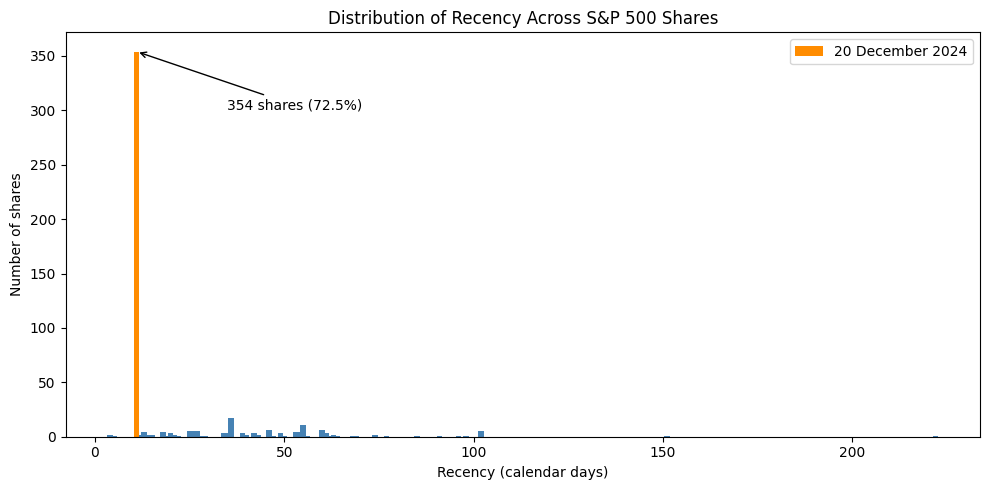

In [21]:
# Task 1.5: Recency distribution
# Check how many shares had their last high-volume event 11 days before the observation date.

import matplotlib.pyplot as plt

recency = feature_table["Recency_Days"].astype(int)
recency_counts = recency.value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(recency_counts.index, recency_counts.values,
        color="steelblue", width=1.5)

# Highlight the 11-day Recency value
plt.bar(11, recency_counts.loc[11], color="darkorange", width=1.5,
        label="20 December 2024")

plt.annotate(
    f"{recency_counts.loc[11]} shares (72.5%)",
    xy=(11, recency_counts.loc[11]),
    xytext=(35, recency_counts.loc[11] * 0.85),
    arrowprops=dict(arrowstyle="->"),
    fontsize=10
)

plt.title("Distribution of Recency Across S&P 500 Shares")
plt.xlabel("Recency (calendar days)")
plt.ylabel("Number of shares")
plt.legend()
plt.tight_layout()
plt.show()

# Task 2 — Stock Segmentation and Sensitivity Analysis
## 2.1 Feature Preparation
### 2.1.1 Separate Risk–Return and RFM Feature Matrices

In [22]:
# Create two feature matrices for separate clustering analyses.

risk_features = feature_table[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].astype(float).copy()

rfm_features_task2 = feature_table[
    ["Recency_Days", "Frequency_60", "Monetary_60_USD"]
].astype(float).copy()

# Check that both datasets contain the same shares.
assert risk_features.index.equals(rfm_features_task2.index)

print("Risk-return matrix:", risk_features.shape)
print("RFM matrix:", rfm_features_task2.shape)

print("\nRisk-return features:")
display(risk_features.head())

print("\nRFM features:")
display(rfm_features_task2.head())

Risk-return matrix: (488, 2)
RFM matrix: (488, 3)

Risk-return features:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
MMM,0.001142,0.869080
AOS,0.001991,1.042804
ABT,0.000971,0.583543
ABBV,0.003749,0.425366
ACN,0.002376,1.143300



RFM features:


,Recency_Days,Frequency_60,Monetary_60_USD
Ticker,,,
MMM,11.0,4.0,2.599146e+10
AOS,11.0,2.0,4.748980e+09
ABT,11.0,1.0,3.523027e+10
ABBV,11.0,3.0,6.837054e+10
ACN,11.0,2.0,5.199430e+10


Exploratory Data Analysis — Distribution, Skewness and Outliers

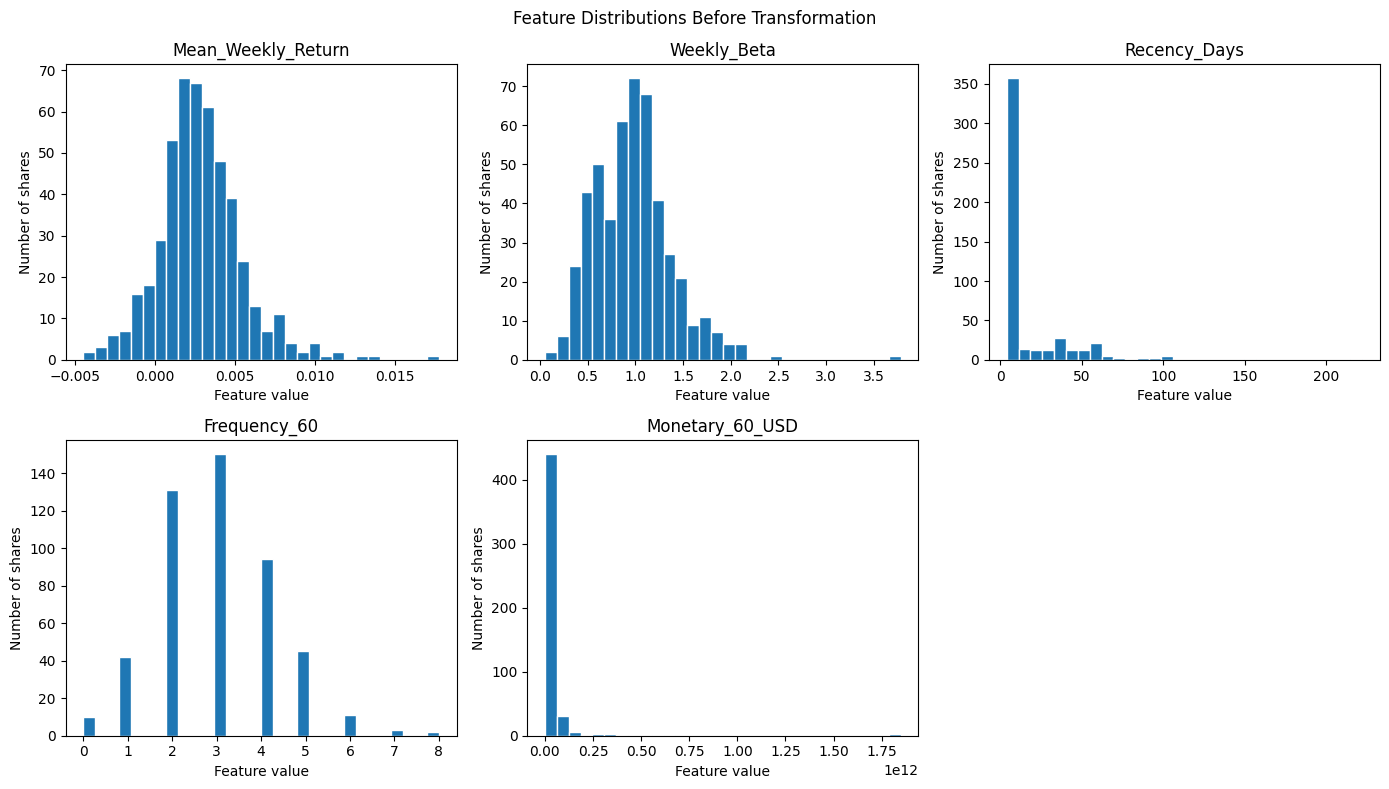

,Skewness,Potential_Outliers,Minimum,Median,Maximum
Feature,,,,,
Mean_Weekly_Return,0.869,15,-4.000000e-03,3.000000e-03,1.800000e-02
Weekly_Beta,1.104,10,5.500000e-02,9.510000e-01,3.779000e+00
Recency_Days,3.653,113,4.000000e+00,1.100000e+01,2.220000e+02
Frequency_60,0.429,2,0.000000e+00,3.000000e+00,8.000000e+00
Monetary_60_USD,11.707,45,1.297483e+09,1.668382e+10,1.847697e+12


In [23]:
# Task 2.1.2: Check the distribution and potential outliers of each feature.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Combine the two matrices for EDA only, not for clustering.
eda_features = pd.concat([risk_features, rfm_features_task2], axis=1)

eda_results = []

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for col, ax in zip(eda_features.columns, axes.flatten()):
    values = eda_features[col].dropna()

    # Calculate skewness and identify possible outliers using 1.5 × IQR.
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (values < lower) | (values > upper)

    eda_results.append({
        "Feature": col,
        "Skewness": values.skew(),
        "Potential_Outliers": outliers.sum(),
        "Minimum": values.min(),
        "Median": values.median(),
        "Maximum": values.max()
    })

    ax.hist(values, bins=30, edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Number of shares")

axes.flatten()[-1].axis("off")

plt.suptitle("Feature Distributions Before Transformation")
plt.tight_layout()
plt.show()

eda_summary = pd.DataFrame(eda_results).set_index("Feature")
display(eda_summary.round(3))


### Feature Distribution Checks and Transformation Decisions

| Feature | Skew | IQR flags | Decision and rationale |
|:---|---:|---:|:---|
| Weekly Return | 0.869 | 15 | kept the original values because the skew was moderate and some returns were negative making log1p unsuitable. |
| Beta | 1.104 | 10 | kept the original values because the higher beta values shows interpretable differences in market sensitivity. |
| Recency | 3.653 | 113 | Tested with log1p but decided to keep the original values as outliers here are not necessarily errors. |
| Frequency | 0.429 | 2 | kept the original values because frequency is a count variable and its skew was low. |
| Monetary | 11.707 | 45 | applied log1p because a few extremely high traded values made the distribution heavily right-skewed. |


Normality Assessment and Monetary Transformation

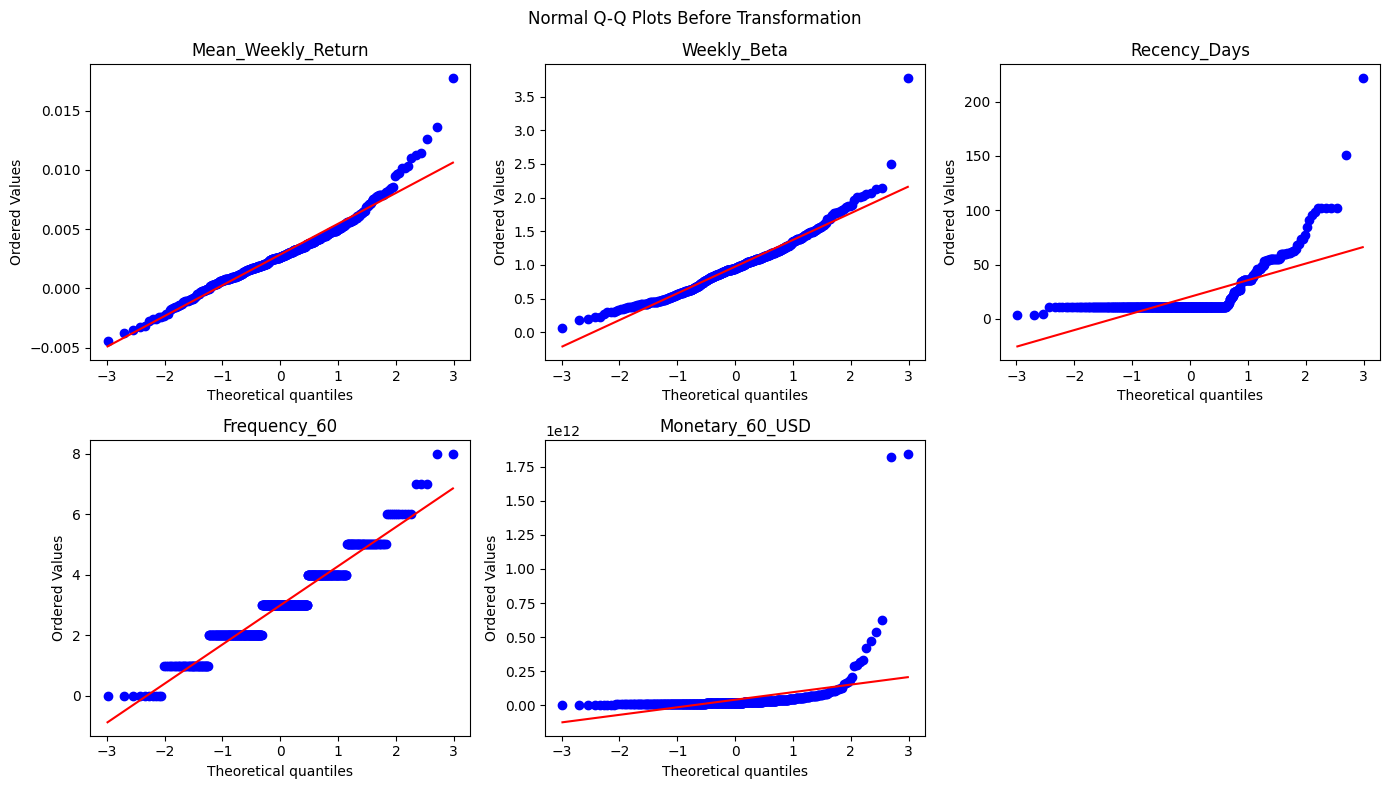

In [24]:
# Compare each feature with a theoretical normal distribution.

from scipy import stats

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for col, ax in zip(eda_features.columns, axes.flatten()):
    stats.probplot(eda_features[col].dropna(), dist="norm", plot=ax)
    ax.set_title(col)

axes.flatten()[-1].axis("off")

plt.suptitle("Normal Q-Q Plots Before Transformation")
plt.tight_layout()
plt.show()

Transform Monetary and compare before and after

,Skewness,Potential_Outliers
Original Monetary,11.707,45
log1p Monetary,1.084,13


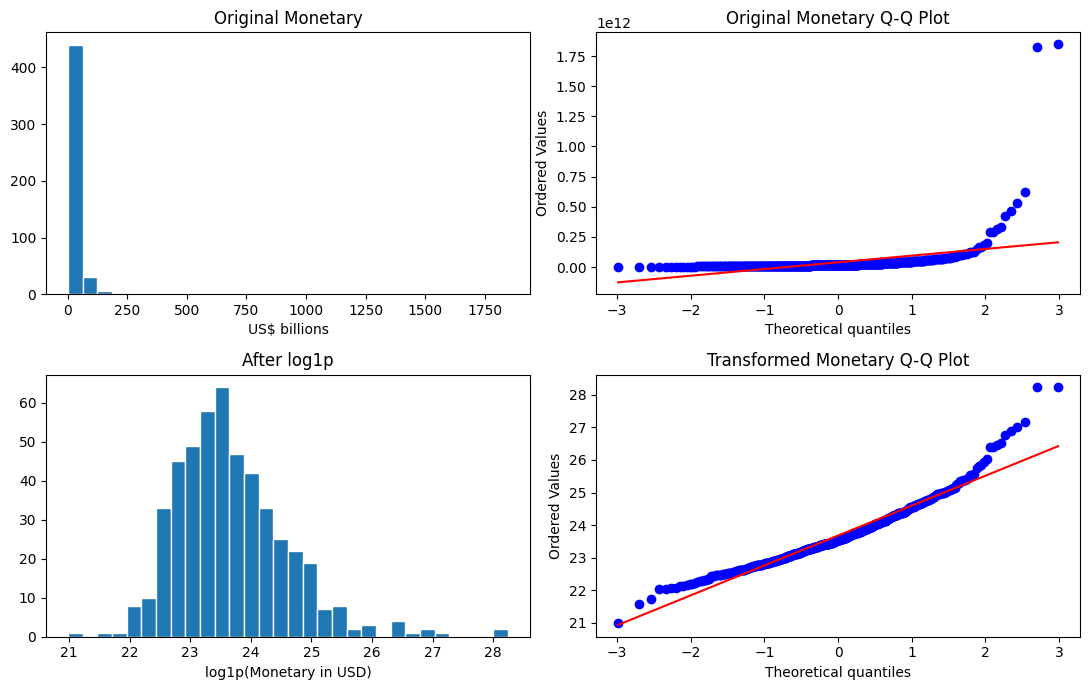

In [25]:
# Apply log1p to reduce the strong right skew in Monetary.
# Keep the original values for reporting cluster profiles later.

monetary_original = rfm_features_task2["Monetary_60_USD"]
monetary_log = np.log1p(monetary_original)

def iqr_count(values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((values < q1 - 1.5 * iqr) |
                (values > q3 + 1.5 * iqr)).sum())

comparison = pd.DataFrame({
    "Skewness": [
        monetary_original.skew(),
        monetary_log.skew()
    ],
    "Potential_Outliers": [
        iqr_count(monetary_original),
        iqr_count(monetary_log)
    ]
}, index=["Original Monetary", "log1p Monetary"])

display(comparison.round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].hist(monetary_original / 1e9, bins=30, edgecolor="white")
axes[0, 0].set_title("Original Monetary")
axes[0, 0].set_xlabel("US$ billions")

stats.probplot(monetary_original, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Original Monetary Q-Q Plot")

axes[1, 0].hist(monetary_log, bins=30, edgecolor="white")
axes[1, 0].set_title("After log1p")
axes[1, 0].set_xlabel("log1p(Monetary in USD)")

stats.probplot(monetary_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Transformed Monetary Q-Q Plot")

plt.tight_layout()
plt.show()

Treatment for Other Skewed Variables

,Skewness,Potential_Outliers
Original Recency,3.653,113
log1p Recency,1.584,113


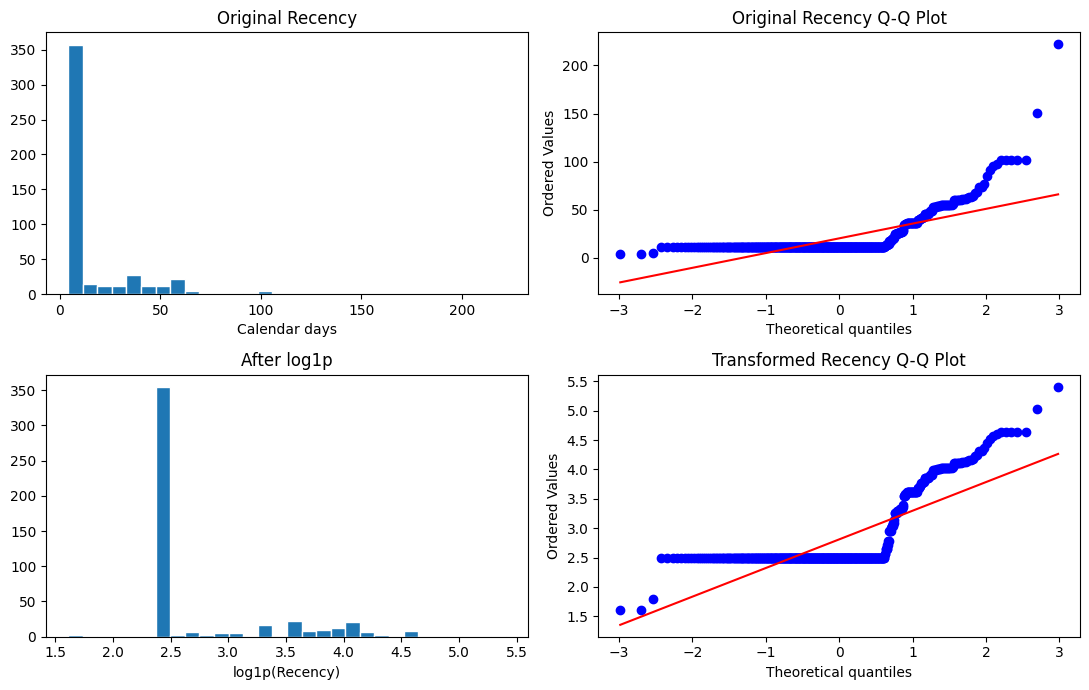

In [26]:
# Check whether log1p reduces the skewness of Recency.

recency_original = rfm_features_task2["Recency_Days"]
recency_log = np.log1p(recency_original)

recency_comparison = pd.DataFrame({
    "Skewness": [
        recency_original.skew(),
        recency_log.skew()
    ],
    "Potential_Outliers": [
        iqr_count(recency_original),
        iqr_count(recency_log)
    ]
}, index=["Original Recency", "log1p Recency"])

display(recency_comparison.round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].hist(recency_original, bins=30, edgecolor="white")
axes[0, 0].set_title("Original Recency")
axes[0, 0].set_xlabel("Calendar days")

stats.probplot(recency_original, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Original Recency Q-Q Plot")

axes[1, 0].hist(recency_log, bins=30, edgecolor="white")
axes[1, 0].set_title("After log1p")
axes[1, 0].set_xlabel("log1p(Recency)")

stats.probplot(recency_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Transformed Recency Q-Q Plot")

plt.tight_layout()
plt.show()

### Feature Treatment Decisions

Potential IQR outliers were retained because unusual share returns,
beta or trading activity do not necessarily indicate incorrect data.
Removing them could exclude genuine market behaviour.

Monetary was transformed using log1p because it had the strongest
positive skew (11.707), which fell to 1.084 after transformation.

Recency was also tested using log1p. Although skewness fell from
3.653 to 1.584, the 113 IQR flags remained because many shares
shared the same Recency value. I therefore retained calendar-day
Recency to preserve its interpretation.

Mean weekly return and beta were kept unchanged before scaling
because their skewness was less severe and their original values
remain financially meaningful. Frequency was also kept unchanged
because it is a discrete count with relatively low skewness.

All five features were then standardised separately within their
respective matrices. Standardisation makes scales comparable but
does not make the distributions normal.

Feature Standardisation

In [27]:
# Task 2.1.5: Prepare and standardise the two feature matrices.

from sklearn.preprocessing import StandardScaler

# Keep return, beta, Recency and Frequency unchanged.
# Apply the required log1p transformation to Monetary only.
risk_prepared = risk_features.copy()
rfm_prepared = rfm_features_task2.copy()

rfm_prepared["Monetary_60_USD"] = np.log1p(
    rfm_prepared["Monetary_60_USD"]
)

# Standardise each feature matrix separately.
risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()

risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_prepared),
    index=risk_prepared.index,
    columns=risk_prepared.columns
)

rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_prepared),
    index=rfm_prepared.index,
    columns=rfm_prepared.columns
)

# Check that both matrices contain the same 488 shares.
assert risk_scaled.index.equals(rfm_scaled.index)
assert np.isfinite(risk_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()

print("Risk-return matrix:", risk_scaled.shape)
print("RFM matrix:", rfm_scaled.shape)

print("\nStandardised risk-return features:")
display(risk_scaled.head())

print("\nStandardised RFM features:")
display(rfm_scaled.head())

# Confirm the means are approximately 0 and standard deviations 1.
print("\nRisk-return scaling check:")
display(risk_scaled.agg(["mean", "std"]).round(3))

print("\nRFM scaling check:")
display(rfm_scaled.agg(["mean", "std"]).round(3))

Risk-return matrix: (488, 2)
RFM matrix: (488, 3)

Standardised risk-return features:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
MMM,-0.648704,-0.258014
AOS,-0.327838,0.169738
ABT,-0.713442,-0.961076
ABBV,0.337391,-1.350548
ACN,-0.181922,0.417183



Standardised RFM features:


,Recency_Days,Frequency_60,Monetary_60_USD
Ticker,,,
MMM,-0.441208,0.762582,0.319430
AOS,-0.441208,-0.744058,-1.489612
ABT,-0.441208,-1.497377,0.643107
ABBV,-0.441208,0.009262,1.348739
ACN,-0.441208,-0.744058,1.057340



Risk-return scaling check:


,Mean_Weekly_Return,Weekly_Beta
mean,-0.000,-0.000
std,1.001,1.001



RFM scaling check:


,Recency_Days,Frequency_60,Monetary_60_USD
mean,-0.000,-0.000,-0.000
std,1.001,1.001,1.001


## 2.2 Agglomerative Clustering


we have 488 shares, and initially every share belongs to its own group.

Agglomerative clustering gradually combines the most similar groups:

2.2.1 Ward Linkage and Dendrograms

we use p=30. With 488 shares, displaying every ticker would make the dendrogram unreadable. This shows the last 30 merged groups, while the clustering calculation still uses all 488 shares.

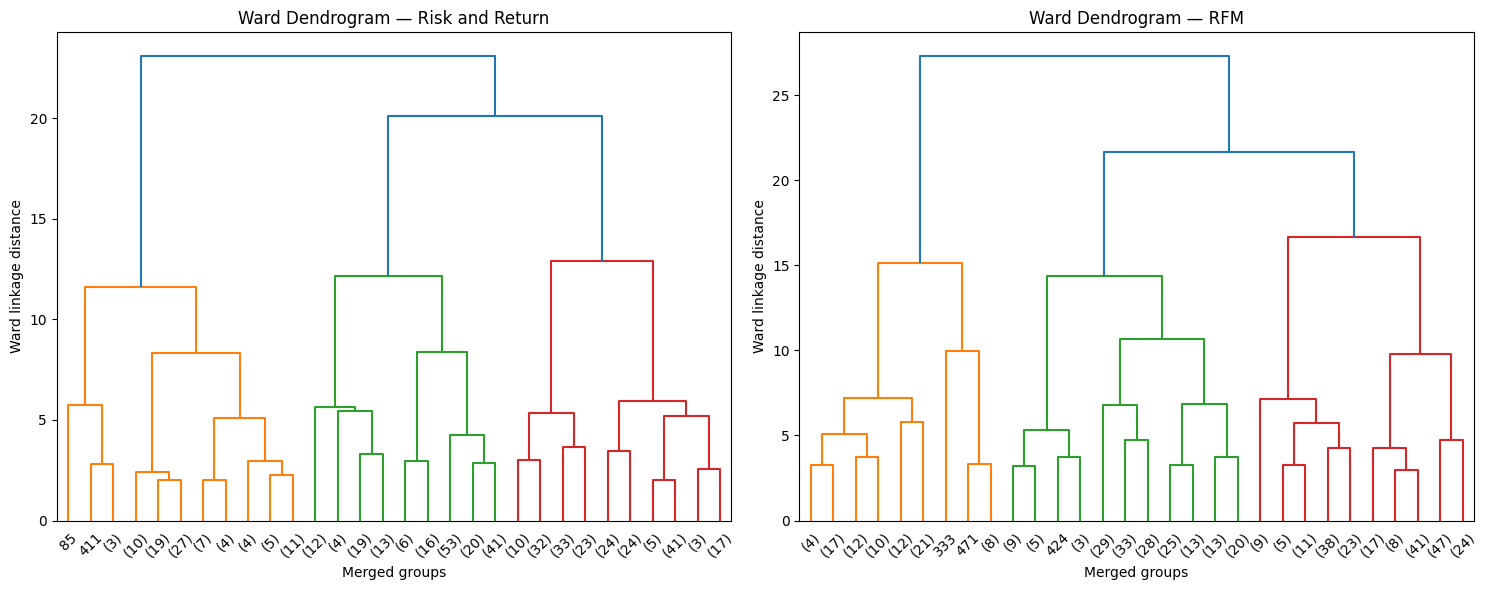

In [28]:
# Task 2.2.1: Apply Ward hierarchical clustering to both matrices.

from scipy.cluster.hierarchy import linkage, dendrogram

# Ward uses Euclidean distances between standardised observations.
ward_risk = linkage(risk_scaled, method="ward", metric="euclidean")
ward_rfm = linkage(rfm_scaled, method="ward", metric="euclidean")

# Display the final 30 merged groups for readability.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

dendrogram(
    ward_risk,
    truncate_mode="lastp",
    p=30,
    ax=axes[0]
)
axes[0].set_title("Ward Dendrogram — Risk and Return")
axes[0].set_xlabel("Merged groups")
axes[0].set_ylabel("Ward linkage distance")

dendrogram(
    ward_rfm,
    truncate_mode="lastp",
    p=30,
    ax=axes[1]
)
axes[1].set_title("Ward Dendrogram — RFM")
axes[1].set_xlabel("Merged groups")
axes[1].set_ylabel("Ward linkage distance")

plt.tight_layout()
plt.show()


### Dendrogram Interpretation

| Observation | Risk–Return Dendrogram | RFM Dendrogram |
|:---|:---|:---|
| Final merge height | Approximately 23 | Approximately 27 |
| Major merges | Around heights 20 and 23 | Around heights 22 and 27 |
| Visible branches | Three broad coloured branches | Three broad coloured branches |
| Interpretation | Three clusters may be worth investigating | Three clusters may be worth investigating |

**Key observations:**

- The three coloured branches suggest that **k = 3 is worth investigating**, but do not prove it is the optimal choice.
- The greater height of the RFM dendrogram does not mean better or worse clustering, as the analyses use different numbers of features.
- Numbers in brackets at the bottom represent the number of original observations within collapsed branches, not ticker names or cluster labels.


2.2.2 Evaluating Cluster Counts (k = 2 to 8)

1. Silhouette score: Measures whether shares are close to others in their own cluster and relatively far from other clusters. Scores closer to +1 generally indicate better-separated clusters.

2. Cluster sizes: Shows how many shares belong to each group. For example, a solution with 480 shares in one cluster and only 8 in another may be less useful for practical segmentation, even if its silhouette score is high.

In [29]:
# Task 2.2.2: Compare Ward clustering solutions from 2 to 8 clusters.

from scipy.cluster.hierarchy import cut_tree
from sklearn.metrics import silhouette_score

ward_results = []

for name, tree, scaled in [
    ("Risk-Return", ward_risk, risk_scaled),
    ("RFM", ward_rfm, rfm_scaled)
]:
    for k in range(2, 9):

        # Cut the hierarchy into k clusters.
        labels = cut_tree(tree, n_clusters=k).ravel()

        # Evaluate separation using the standardised features.
        score = silhouette_score(scaled, labels)

        # Check how many shares belong to each cluster.
        sizes = pd.Series(labels).value_counts().sort_values()

        ward_results.append({
            "Matrix": name,
            "Clusters": k,
            "Silhouette": round(score, 3),
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Cluster_Sizes": sorted(sizes.tolist(), reverse=True)
        })

ward_evaluation = pd.DataFrame(ward_results)

display(ward_evaluation)

,Matrix,Clusters,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk-Return,2,0.340,92,396,"[396, 92]"
1,Risk-Return,3,0.293,92,212,"[212, 184, 92]"
2,Risk-Return,4,0.265,92,184,"[184, 114, 98, 92]"
3,Risk-Return,5,0.287,48,136,"[136, 114, 98, 92, 48]"
4,Risk-Return,6,0.304,5,136,"[136, 114, 98, 87, 48, 5]"
5,Risk-Return,7,0.306,5,114,"[114, 114, 98, 87, 48, 22, 5]"
6,Risk-Return,8,0.314,5,114,"[114, 114, 98, 56, 48, 31, 22, 5]"
7,RFM,2,0.369,86,402,"[402, 86]"
8,RFM,3,0.261,86,223,"[223, 179, 86]"
9,RFM,4,0.251,86,179,"[179, 137, 86, 86]"



 Cluster count Decisions

| Method and matrix | k = 2 silhouette | Selected k | Selected silhouette | Main justification |
|:---|:---:|:---:|:---:|:---|
| Ward Risk–Return | 0.340 | **3** | 0.293 | distinguishes lower-return/higher-beta shares from moderate-return/lower-beta shares. |
| Ward RFM | 0.369 | **3** | 0.261 | identifies differences in traded values among recently active shares. |
| K-means Risk–Return | 0.387 | **3** | 0.328 | Gives three meaningful return–beta combinations without creating very small groups. |
| K-means RFM | 0.424 | **4** | 0.341 | distinguishes differences in trading frequency and traded values clearly. |


Cluster Profiles and Final Cluster Count Selection

Compare Cluster Profiles Before Selecting k

A silhouette score tells us how well the groups are separated, but it does not explain what makes the groups different.

For example, one risk–return cluster might contain shares with higher beta and higher mean returns, while another might contain shares with lower beta.

Similarly, an RFM group might contain shares with more frequent high-volume activity.

We need to examine the average original feature values for each group, not the standardised numbers. This makes the results meaningful to an investment analyst.

We'll compare k = 2 and k = 3 for both matrices first, since they have reasonable cluster sizes and are the main candidates.

In [30]:
# Compare Ward cluster profiles for k = 2 and k = 3.
# Use original units so the groups are easier to interpret.

for name, tree, original in [
    ("Risk-Return", ward_risk, risk_features),
    ("RFM", ward_rfm, rfm_features_task2)
]:
    for k in [2, 3]:

        labels = cut_tree(tree, n_clusters=k).ravel() + 1

        profiles = original.copy()
        profiles["Cluster"] = labels

        # Convert units for easier interpretation.
        if name == "Risk-Return":
            profiles["Mean_Weekly_Return"] *= 100
        else:
            profiles["Monetary_60_USD"] /= 1e9

        summary = profiles.groupby("Cluster").agg(
            {**{col: "mean" for col in original.columns},
             "Cluster": "size"}
        ).rename(columns={"Cluster": "Shares"})

        print(f"\n{name} — Ward clustering (k = {k})")
        display(summary.round(3))


Risk-Return — Ward clustering (k = 2)


,Mean_Weekly_Return,Weekly_Beta,Shares
Cluster,,,
1,0.205,0.899,396
2,0.632,1.298,92



Risk-Return — Ward clustering (k = 3)


,Mean_Weekly_Return,Weekly_Beta,Shares
Cluster,,,
1,0.154,1.200,184
2,0.250,0.637,212
3,0.632,1.298,92



RFM — Ward clustering (k = 2)


,Recency_Days,Frequency_60,Monetary_60_USD,Shares
Cluster,,,,
1,12.557,3.204,37.389,402
2,57.000,1.977,48.248,86



RFM — Ward clustering (k = 3)


,Recency_Days,Frequency_60,Monetary_60_USD,Shares
Cluster,,,,
1,12.145,2.939,70.249,179
2,12.888,3.417,11.013,223
3,57.000,1.977,48.248,86


Selected Ward Cluster Assignments

we need to give every share its final Ward cluster label, which we'll use for comparison with K-means in Task 2.4 and the RFM sensitivity test in Task 2.5.

In [31]:
# Save the selected Ward clusters for both feature matrices.

ward_risk_k = 3
ward_rfm_k = 3

ward_risk_labels = pd.Series(
    cut_tree(ward_risk, n_clusters=ward_risk_k).ravel() + 1,
    index=risk_scaled.index,
    name="Ward_Risk_Cluster"
)

ward_rfm_labels = pd.Series(
    cut_tree(ward_rfm, n_clusters=ward_rfm_k).ravel() + 1,
    index=rfm_scaled.index,
    name="Ward_RFM_Cluster"
)

# Keep the assignments together for later comparison.
ward_assignments = pd.concat(
    [ward_risk_labels, ward_rfm_labels], axis=1
)

print("Risk-return cluster sizes:")
print(ward_risk_labels.value_counts().sort_index())

print("\nRFM cluster sizes:")
print(ward_rfm_labels.value_counts().sort_index())

display(ward_assignments.head())

Risk-return cluster sizes:
Ward_Risk_Cluster
1    184
2    212
3     92
Name: count, dtype: int64

RFM cluster sizes:
Ward_RFM_Cluster
1    179
2    223
3     86
Name: count, dtype: int64


,Ward_Risk_Cluster,Ward_RFM_Cluster
Ticker,,
MMM,1,1
AOS,1,2
ABT,2,1
ABBV,2,1
ACN,1,1



### Cluster Selection: Silhouette Scores and Rationale

| Matrix | k = 2 silhouette | k = 3 silhouette | Selected k | Reason |
|:---|:---:|:---:|:---:|:---|
| Risk–Return | 0.340 | 0.293 | **3** | Separates different return–beta combinations |
| RFM | 0.369 | 0.261 | **3** | Distinguishes traded-value levels within recent-activity shares |




| Risk–Return cluster | Profile | Number of shares |
|---|---|---:|
| 1 | Lower return, higher beta group | 184 |
| 2 | Moderate return, lower beta group | 212 |
| 3 | Higher return, higher beta group | 92 |



## 2.3 K-means Clustering
### 2.3.1 Evaluating K-means (k = 2 to 8)

K-means is suitable: It is efficient for 488 shares and works well with compact groups in standardised numeric data. However, it is sensitive to extreme values, depends on the selected \(k\), and may perform poorly when groups are irregularly shaped.

In [32]:
# Task 2.3.1: Compare K-means solutions from 2 to 8 clusters.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_results = []

for name, scaled in [
    ("Risk-Return", risk_scaled),
    ("RFM", rfm_scaled)
]:
    for k in range(2, 9):

        # Use a fixed seed and 20 initialisations for reproducibility.
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(scaled)

        # Compare cluster separation, inertia and group sizes.
        sizes = pd.Series(labels).value_counts()

        kmeans_results.append({
            "Matrix": name,
            "Clusters": k,
            "Silhouette": round(silhouette_score(scaled, labels), 3),
            "Inertia": round(model.inertia_, 3),
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Cluster_Sizes": sorted(sizes.tolist(), reverse=True)
        })

kmeans_evaluation = pd.DataFrame(kmeans_results)

display(kmeans_evaluation)

,Matrix,Clusters,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk-Return,2,0.387,625.010,143,345,"[345, 143]"
1,Risk-Return,3,0.328,464.077,119,203,"[203, 166, 119]"
2,Risk-Return,4,0.325,373.936,41,167,"[167, 149, 131, 41]"
3,Risk-Return,5,0.340,311.548,27,171,"[171, 131, 109, 50, 27]"
4,Risk-Return,6,0.334,266.914,5,160,"[160, 112, 111, 57, 43, 5]"
5,Risk-Return,7,0.355,228.714,16,143,"[143, 87, 80, 76, 48, 38, 16]"
6,Risk-Return,8,0.358,196.139,5,139,"[139, 81, 76, 72, 48, 37, 30, 5]"
7,RFM,2,0.424,1071.585,68,420,"[420, 68]"
8,RFM,3,0.325,800.746,63,274,"[274, 151, 63]"
9,RFM,4,0.341,612.475,61,214,"[214, 122, 91, 61]"


 K-means Cluster-count Decisions

| Matrix | k = 2 silhouette | Selected k | Selected silhouette | Reason |
|:---|:---:|:---:|:---:|:---|
| Risk–Return | 0.387 | **3** | 0.328 | Three balanced, interpretable risk–return profiles |
| RFM | 0.424 | **4** | 0.341 | Separates event frequency and traded-value differences |


2.3.2 — Elbow Method

use the evaluation results to create an Elbow plot and a Silhouette plot for each feature matrix

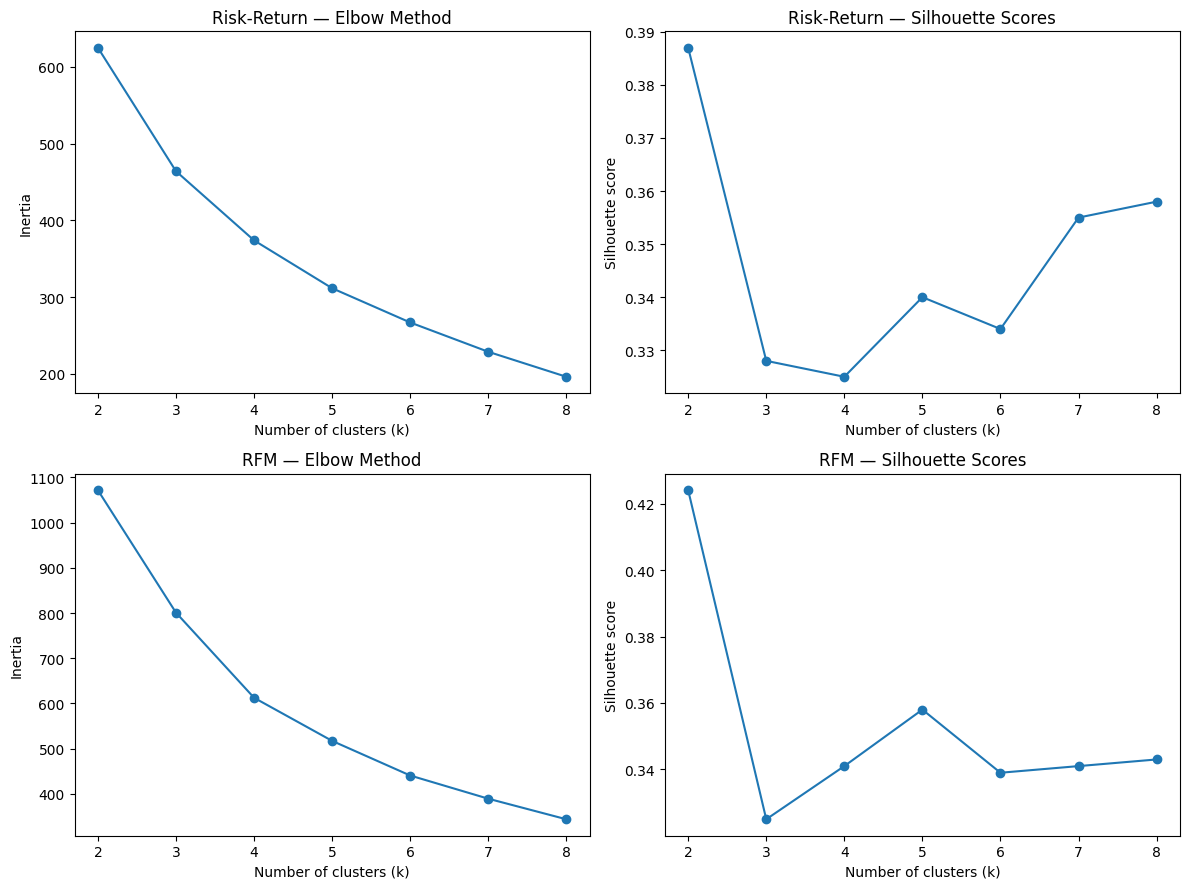

In [33]:
# Task 2.3.2: Plot inertia and silhouette scores for K-means.

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for row, name in enumerate(["Risk-Return", "RFM"]):

    results = kmeans_evaluation[
        kmeans_evaluation["Matrix"] == name
    ]

    axes[row, 0].plot(
        results["Clusters"],
        results["Inertia"],
        marker="o"
    )
    axes[row, 0].set_title(f"{name} — Elbow Method")
    axes[row, 0].set_xlabel("Number of clusters (k)")
    axes[row, 0].set_ylabel("Inertia")

    axes[row, 1].plot(
        results["Clusters"],
        results["Silhouette"],
        marker="o"
    )
    axes[row, 1].set_title(f"{name} — Silhouette Scores")
    axes[row, 1].set_xlabel("Number of clusters (k)")
    axes[row, 1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

Compare K-means Cluster Profiles and Final K Selection

measured how well the clusters are separated, but still don't know what makes the shares in each cluster different.

For example, a Risk–Return cluster might contain shares with high weekly returns and high beta. An RFM cluster might contain shares with recent high-volume events but relatively low traded value.

calculated the average feature values for each candidate group in original units, just as we did for Ward.

In [34]:
# Task 2.3.3: Compare K-means cluster profiles in original units.

for name, scaled, original, candidates in [
    ("Risk-Return", risk_scaled, risk_features, [2, 3, 4]),
    ("RFM", rfm_scaled, rfm_features_task2, [2, 3, 4, 5])
]:
    for k in candidates:

        model = KMeans(n_clusters=k, random_state=42, n_init=20)
        labels = model.fit_predict(scaled) + 1

        profiles = original.copy()
        profiles["Cluster"] = labels

        # Convert the units for easier interpretation.
        if name == "Risk-Return":
            profiles["Mean_Weekly_Return"] *= 100
        else:
            profiles["Monetary_60_USD"] /= 1e9

        summary = profiles.groupby("Cluster").agg(
            {**{col: "mean" for col in original.columns},
             "Cluster": "size"}
        ).rename(columns={"Cluster": "Shares"})

        print(f"\n{name} — K-means (k = {k})")
        display(summary.round(3))


Risk-Return — K-means (k = 2)


,Mean_Weekly_Return,Weekly_Beta,Shares
Cluster,,,
1,0.533,1.350,143
2,0.183,0.818,345



Risk-Return — K-means (k = 3)


,Mean_Weekly_Return,Weekly_Beta,Shares
Cluster,,,
1,0.096,1.139,166
2,0.260,0.632,203
3,0.596,1.326,119



Risk-Return — K-means (k = 4)


,Mean_Weekly_Return,Weekly_Beta,Shares
Cluster,,,
1,0.447,0.968,167
2,0.721,1.700,41
3,0.161,0.573,149
4,0.086,1.209,131


... (4 outputs left out)


RFM — K-means (k = 4)


,Recency_Days,Frequency_60,Monetary_60_USD,Shares
Cluster,,,,
1,13.943,4.549,15.015,122
2,66.016,1.672,56.180,61
3,13.290,2.369,15.171,214
4,15.143,3.231,117.301,91



RFM — K-means (k = 5)


,Recency_Days,Frequency_60,Monetary_60_USD,Shares
Cluster,,,,
1,14.092,3.241,120.713,87
2,113.909,0.091,184.004,11
3,11.630,2.355,15.121,200
4,13.943,4.549,15.015,122
5,50.647,2.191,26.437,68


Save the selected Final K-means Cluster Assignments

k = 3 for Risk–Return K-means.

Although k = 2 has a stronger silhouette score, k = 3 provides more informative segmentation, with no very small clusters. It also allows a useful comparison with the three-cluster Ward solution.

k = 4 for RFM K-means.

The silhouette at k = 4 is 0.341, compared with 0.325 at k = 3 and 0.424 at k = 2. So k = 2 has better separation, but k = 4 offers more detail, with a smallest cluster of 61 shares.

At k = 5, the 11-share group has average Recency of 113.9 days and Frequency of just 0.091. This is interesting but creates a small, specialised group. For our main segmentation, k = 4 is easier to interpret without making the groups excessively small.

In [35]:
# Task 2.3.4: Fit and save the selected K-means solutions.

kmeans_risk_k = 3
kmeans_rfm_k = 4

# Fit K-means using the same settings as our evaluation.
kmeans_risk_model = KMeans(
    n_clusters=kmeans_risk_k,
    random_state=42,
    n_init=20
)

kmeans_rfm_model = KMeans(
    n_clusters=kmeans_rfm_k,
    random_state=42,
    n_init=20
)

# Assign each share to its cluster.
kmeans_risk_labels = pd.Series(
    kmeans_risk_model.fit_predict(risk_scaled) + 1,
    index=risk_scaled.index,
    name="KMeans_Risk_Cluster"
)

kmeans_rfm_labels = pd.Series(
    kmeans_rfm_model.fit_predict(rfm_scaled) + 1,
    index=rfm_scaled.index,
    name="KMeans_RFM_Cluster"
)

# Combine the two assignments for later comparison.
kmeans_assignments = pd.concat(
    [kmeans_risk_labels, kmeans_rfm_labels],
    axis=1
)

print("Risk-return K-means cluster sizes:")
print(kmeans_risk_labels.value_counts().sort_index())

print("\nRFM K-means cluster sizes:")
print(kmeans_rfm_labels.value_counts().sort_index())

display(kmeans_assignments.head())

Risk-return K-means cluster sizes:
KMeans_Risk_Cluster
1    166
2    203
3    119
Name: count, dtype: int64

RFM K-means cluster sizes:
KMeans_RFM_Cluster
1    122
2     61
3    214
4     91
Name: count, dtype: int64


,KMeans_Risk_Cluster,KMeans_RFM_Cluster
Ticker,,
MMM,1,1
AOS,1,3
ABT,2,3
ABBV,2,4
ACN,1,4


# Task 2.4 — Cluster Profiles and Algorithm Comparison

2.4.1 — Compare Ward and K-means cluster memberships

In [36]:
# Task 2.4.1: Compare Ward and K-means on the same 488 shares.

from sklearn.metrics import adjusted_rand_score

# Combine the four cluster assignments by ticker.
cluster_comparison = pd.concat(
    [ward_assignments, kmeans_assignments],
    axis=1
)

assert len(cluster_comparison) == 488
assert cluster_comparison.notna().all().all()

# Compare which shares are grouped together.
risk_cross = pd.crosstab(
    cluster_comparison["Ward_Risk_Cluster"],
    cluster_comparison["KMeans_Risk_Cluster"]
)

rfm_cross = pd.crosstab(
    cluster_comparison["Ward_RFM_Cluster"],
    cluster_comparison["KMeans_RFM_Cluster"]
)

print("Risk-Return: Ward vs K-means")
display(risk_cross)

print("\nRFM: Ward vs K-means")
display(rfm_cross)

# ARI measures agreement without relying on cluster numbers.
risk_ari = adjusted_rand_score(
    ward_risk_labels,
    kmeans_risk_labels
)

rfm_ari = adjusted_rand_score(
    ward_rfm_labels,
    kmeans_rfm_labels
)

print(f"Risk-Return ARI: {risk_ari:.3f}")
print(f"RFM ARI: {rfm_ari:.3f}")

Risk-Return: Ward vs K-means


KMeans_Risk_Cluster,1,2,3
Ward_Risk_Cluster,,,
1,146,22,16
2,18,181,13
3,2,0,90



RFM: Ward vs K-means


KMeans_RFM_Cluster,1,2,3,4
Ward_RFM_Cluster,,,,
1,14,0,82,83
2,107,0,116,0
3,1,61,16,8


Risk-Return ARI: 0.602
RFM ARI: 0.287


Cluster Profiles and Two-Dimensional Visualisations

RFM variance explained by each PCA component:
[0.458 0.336]
Total variance explained: 79.44 %


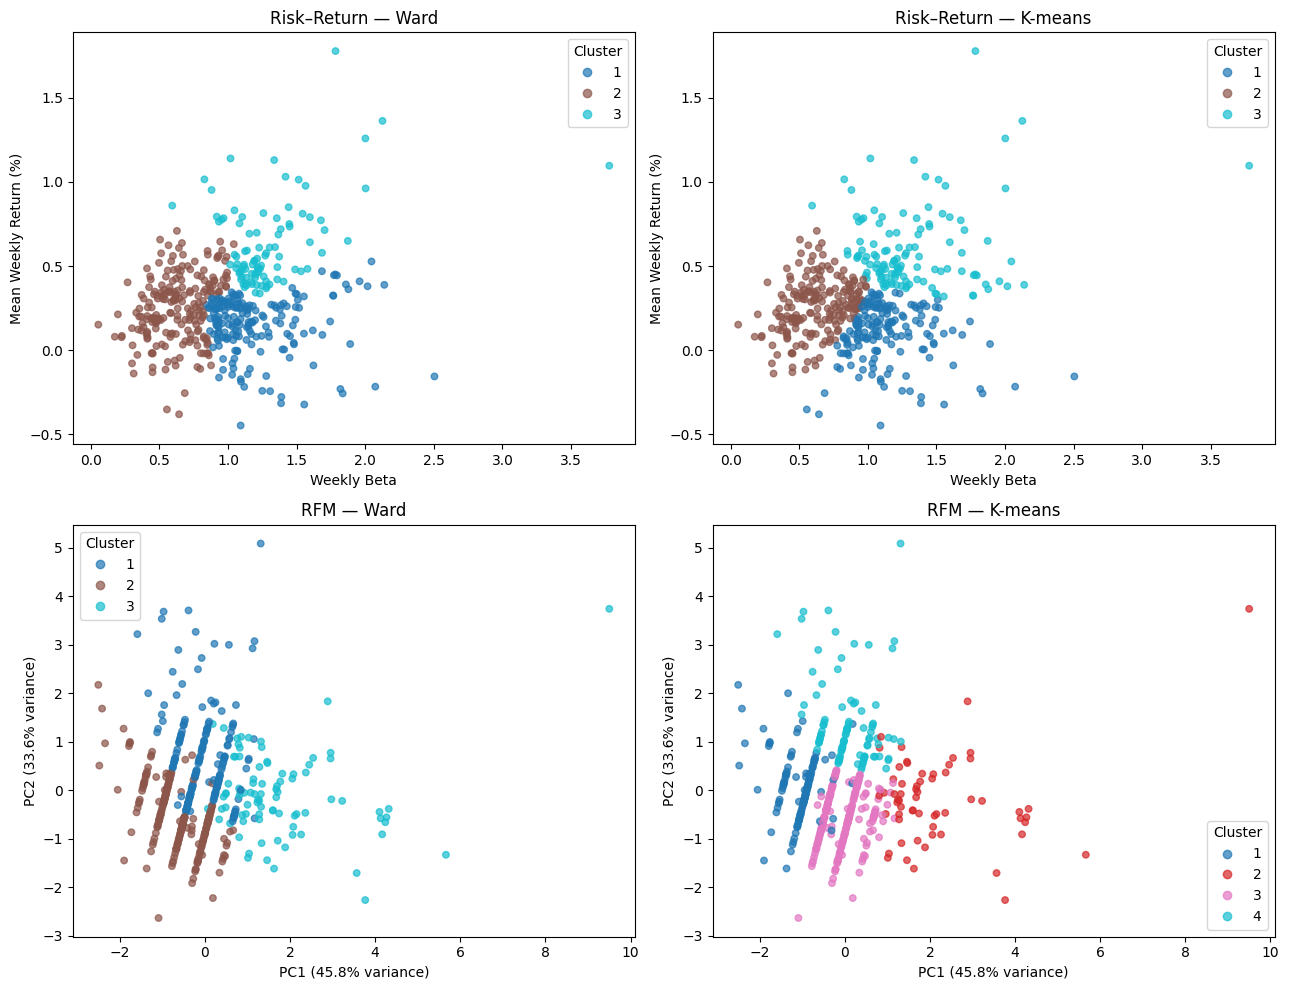

In [37]:
# Task 2.4.2: Visualise Ward and K-means clusters.

from sklearn.decomposition import PCA

# Risk-return is already two-dimensional.
risk_plot = risk_features.copy()
risk_plot["Mean_Weekly_Return"] *= 100

# Reduce the three standardised RFM features to two PCA components.
pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

print("RFM variance explained by each PCA component:")
print(pca.explained_variance_ratio_.round(3))

print("Total variance explained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

plots = [
    (axes[0, 0], risk_plot, ward_risk_labels,
     "Risk–Return — Ward"),
    (axes[0, 1], risk_plot, kmeans_risk_labels,
     "Risk–Return — K-means")
]

# Plot Risk–Return clusters in their original units.
for ax, data, labels, title in plots:
    scatter = ax.scatter(
        data["Weekly_Beta"],
        data["Mean_Weekly_Return"],
        c=labels,
        cmap="tab10",
        s=22,
        alpha=0.7
    )

    ax.set_title(title)
    ax.set_xlabel("Weekly Beta")
    ax.set_ylabel("Mean Weekly Return (%)")
    ax.legend(*scatter.legend_elements(), title="Cluster")

# Plot RFM clusters using PCA coordinates.
for ax, labels, title in [
    (axes[1, 0], ward_rfm_labels, "RFM — Ward"),
    (axes[1, 1], kmeans_rfm_labels, "RFM — K-means")
]:
    scatter = ax.scatter(
        rfm_pca[:, 0],
        rfm_pca[:, 1],
        c=labels,
        cmap="tab10",
        s=22,
        alpha=0.7
    )

    ax.set_title(title)
    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)"
    )
    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"
    )
    ax.legend(*scatter.legend_elements(), title="Cluster")

plt.tight_layout()
plt.show()

In [38]:
# Show how the three RFM features contribute to the PCA axes.

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=["Recency", "Frequency", "log1p(Monetary)"],
    columns=["PC1", "PC2"]
)

display(pca_loadings.round(3))

,PC1,PC2
Recency,0.711,0.023
Frequency,-0.650,0.403
log1p(Monetary),0.269,0.915


Ward and K-means identify more similar groups for Risk–Return than for RFM.

Same-k Algorithm Comparison

already compared the algorithms using their selected cluster counts. I also compared them using the same number of clusters.

This way, I can understand how much disagreement is associated with the clustering method rather than the different values of k.

In [39]:
# Compare Ward and K-means using identical cluster counts.
# This helps separate algorithm differences from different choices of k.

same_k_results = []

for name, scaled, ward_tree in [
    ("Risk-Return", risk_scaled, ward_risk),
    ("RFM", rfm_scaled, ward_rfm)
]:
    for k in [3, 4]:

        # Ward labels at the chosen k
        ward_labels = cut_tree(
            ward_tree, n_clusters=k
        ).ravel()

        # K-means labels at the same k
        km_model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        km_labels = km_model.fit_predict(scaled)

        same_k_results.append({
            "Matrix": name,
            "k": k,
            "Ward_Silhouette": silhouette_score(scaled, ward_labels),
            "KMeans_Silhouette": silhouette_score(scaled, km_labels),
            "ARI": adjusted_rand_score(ward_labels, km_labels)
        })

same_k_comparison = pd.DataFrame(same_k_results)

display(same_k_comparison.round(3))

,Matrix,k,Ward_Silhouette,KMeans_Silhouette,ARI
0,Risk-Return,3,0.293,0.328,0.602
1,Risk-Return,4,0.265,0.325,0.449
2,RFM,3,0.261,0.325,0.643
3,RFM,4,0.251,0.341,0.372


Final Cluster Profiles in Original Units

In [40]:
# Summarise the four selected clustering solutions.
# Use original units rather than standardised values for interpretation.

for name, original, labels in [
    ("Ward Risk-Return", risk_features, ward_risk_labels),
    ("K-means Risk-Return", risk_features, kmeans_risk_labels),
    ("Ward RFM", rfm_features_task2, ward_rfm_labels),
    ("K-means RFM", rfm_features_task2, kmeans_rfm_labels)
]:
    profiles = original.copy()
    profiles["Cluster"] = labels

    if "Risk-Return" in name:
        profiles["Mean_Weekly_Return"] *= 100
    else:
        profiles["Monetary_60_USD"] /= 1e9

    summary = profiles.groupby("Cluster").agg(
        Shares=("Cluster", "size"),
        **{
            f"{col}_Mean": (col, "mean")
            for col in original.columns
        },
        **{
            f"{col}_Median": (col, "median")
            for col in original.columns
        }
    )

    print(f"\n{name}")
    display(summary.round(3))


Ward Risk-Return


,Shares,Mean_Weekly_Return_Mean,Weekly_Beta_Mean,Mean_Weekly_Return_Median,Weekly_Beta_Median
Cluster,,,,,
1,184,0.154,1.200,0.180,1.089
2,212,0.250,0.637,0.251,0.632
3,92,0.632,1.298,0.550,1.218



K-means Risk-Return


,Shares,Mean_Weekly_Return_Mean,Weekly_Beta_Mean,Mean_Weekly_Return_Median,Weekly_Beta_Median
Cluster,,,,,
1,166,0.096,1.139,0.118,1.081
2,203,0.260,0.632,0.259,0.622
3,119,0.596,1.326,0.528,1.221



Ward RFM


,Shares,Recency_Days_Mean,Frequency_60_Mean,Monetary_60_USD_Mean,Recency_Days_Median,Frequency_60_Median,Monetary_60_USD_Median
Cluster,,,,,,,
1,179,12.145,2.939,70.249,11.0,3.0,34.321
2,223,12.888,3.417,11.013,11.0,3.0,10.140
3,86,57.000,1.977,48.248,54.0,2.0,21.450



K-means RFM


,Shares,Recency_Days_Mean,Frequency_60_Mean,Monetary_60_USD_Mean,Recency_Days_Median,Frequency_60_Median,Monetary_60_USD_Median
Cluster,,,,,,,
1,122,13.943,4.549,15.015,11.0,4.0,12.826
2,61,66.016,1.672,56.180,55.0,2.0,21.242
3,214,13.290,2.369,15.171,11.0,2.0,13.336
4,91,15.143,3.231,117.301,11.0,3.0,60.183


# Task 2.5 — RFM Sensitivity and Correlated Inputs

Imagine two features that give very similar information. For example, if shares with higher Frequency also tend to have higher Monetary, the algorithm may give greater overall influence to that related aspect of trading activity.

Even after standardisation, correlated features can reinforce each other.

Standardisation puts features on comparable scales. It does not remove relationships between them.

To investigate this, we'll calculate the Pearson correlation coefficient, which ranges from −1 to +1.
- Near +1: Two features tend to increase together.
- Near −1: One tends to decrease as the other increases.
- Near 0: Little linear relationship.
Correlation alone does not prove that one feature dominates clustering. That's why we'll perform the removal test in Section 2.5.2.

RFM Correlation Matrix:


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.346,0.153
Frequency,-0.346,1.000,0.013
log1p(Monetary),0.153,0.013,1.000


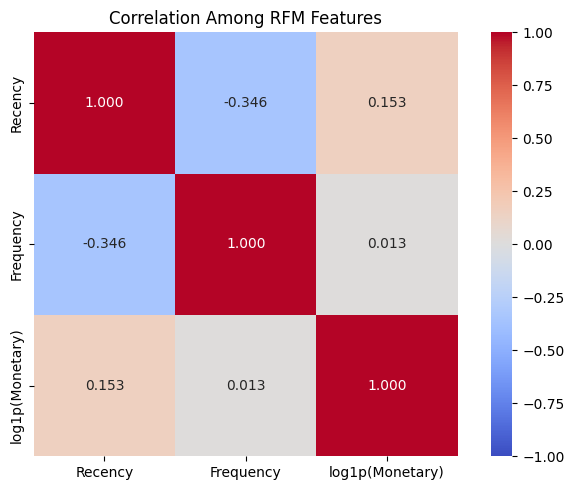

In [41]:
# Task 2.5.1: Check correlations among R, F and log1p(M).

# Use the prepared features before standardisation.
rfm_correlation_data = rfm_prepared.rename(columns={
    "Recency_Days": "Recency",
    "Frequency_60": "Frequency",
    "Monetary_60_USD": "log1p(Monetary)"
})

# Calculate Pearson correlations.
rfm_corr = rfm_correlation_data.corr()

print("RFM Correlation Matrix:")
display(rfm_corr.round(3))

# Show the relationships in a heatmap.
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Among RFM Features")
plt.tight_layout()
plt.show()

used rfm_prepared, not the original RFM matrix, because Monetary has already been transformed using log1p. i have followed the coursework requirement to examine correlations among R, F and log1p(M).

Monetary is barely correlated with Frequency, which is different from what was expected.

Our results show no evidence that Frequency and Monetary duplicate the same linear information.

Although correlated features can reinforce each other even after standardisation, these correlations do not establish that Monetary dominates the clustering.

need to test that directly.

Task 2.5.2 — Removing Monetary

To make the test fair, kept:
- The same 488 shares.
- The same selected k = 3.
- The same Ward linkage and Euclidean distance.
- Fresh standardisation using Recency and Frequency only.
Only the inclusion of Monetary changes.

Sensitivity Analysis — Removing Monetary

In [42]:
# Task 2.5.2: Re-run Ward using only Recency and Frequency.

from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

# Remove Monetary but keep the same 488 shares.
rf_features = rfm_features_task2[
    ["Recency_Days", "Frequency_60"]
].copy()

# Standardise the reduced matrix again.
rf_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rf_features),
    index=rf_features.index,
    columns=rf_features.columns
)

# Apply Ward using the original selected RFM cluster count.
ward_rf = linkage(rf_scaled, method="ward", metric="euclidean")

ward_rf_labels = pd.Series(
    cut_tree(ward_rf, n_clusters=ward_rfm_k).ravel() + 1,
    index=rf_scaled.index,
    name="Ward_RF_Cluster"
)

# Check that both solutions use the same shares.
assert ward_rfm_labels.index.equals(ward_rf_labels.index)

# Compare the original RFM and reduced RF memberships.
rf_ari = adjusted_rand_score(
    ward_rfm_labels,
    ward_rf_labels
)

print("Shares compared:", len(rf_features))
print("Selected number of clusters:", ward_rfm_k)

print("\nReduced RF cluster sizes:")
print(ward_rf_labels.value_counts().sort_index())

print(f"\nAdjusted Rand Index (RFM vs RF): {rf_ari:.3f}")

print("\nCluster membership comparison:")
display(pd.crosstab(
    ward_rfm_labels,
    ward_rf_labels
))

Shares compared: 488
Selected number of clusters: 3

Reduced RF cluster sizes:
Ward_RF_Cluster
1    273
2    125
3     90
Name: count, dtype: int64

Adjusted Rand Index (RFM vs RF): 0.268

Cluster membership comparison:


Ward_RF_Cluster,1,2,3
Ward_RFM_Cluster,,,
1,119,59,1
2,152,66,5
3,2,0,84


need to compare the traded-value profiles of the original and reduced clusters.

In [43]:
# Compare average R, F and M after removing Monetary.
# Monetary is shown for interpretation but was NOT used in the RF clustering.

rf_profile_data = rfm_features_task2.copy()

rf_profile_data["Ward_RFM"] = ward_rfm_labels
rf_profile_data["Ward_RF"] = ward_rf_labels

# Display Monetary in US$ billions.
rf_profile_data["Monetary_60_USD"] /= 1e9

for label_col in ["Ward_RFM", "Ward_RF"]:

    print(f"\nProfiles for {label_col}:")

    summary = rf_profile_data.groupby(label_col).agg(
        Shares=("Recency_Days", "size"),
        Mean_Recency=("Recency_Days", "mean"),
        Mean_Frequency=("Frequency_60", "mean"),
        Mean_Monetary_USD_Bn=("Monetary_60_USD", "mean"),
        Median_Monetary_USD_Bn=("Monetary_60_USD", "median")
    )

    display(summary.round(3))


Profiles for Ward_RFM:


,Shares,Mean_Recency,Mean_Frequency,Mean_Monetary_USD_Bn,Median_Monetary_USD_Bn
Ward_RFM,,,,,
1,179,12.145,2.939,70.249,34.321
2,223,12.888,3.417,11.013,10.140
3,86,57.000,1.977,48.248,21.450



Profiles for Ward_RF:


,Shares,Mean_Recency,Mean_Frequency,Mean_Monetary_USD_Bn,Median_Monetary_USD_Bn
Ward_RF,,,,,
1,273,12.875,3.853,39.297,14.784
2,125,11.040,1.800,34.338,17.699
3,90,56.167,2.011,46.215,20.490


In [44]:
# Save the final cluster assignments for Tasks 2 and 3.

task2_results = feature_table.copy()

task2_results["Ward_Risk_Cluster"] = ward_risk_labels
task2_results["Ward_RFM_Cluster"] = ward_rfm_labels
task2_results["KMeans_Risk_Cluster"] = kmeans_risk_labels
task2_results["KMeans_RFM_Cluster"] = kmeans_rfm_labels
task2_results["Ward_RF_Cluster"] = ward_rf_labels

# Check the final table and save it.
print("Shares in final results:", len(task2_results))
print("Missing cluster assignments:",
      task2_results[[
          "Ward_Risk_Cluster",
          "Ward_RFM_Cluster",
          "KMeans_Risk_Cluster",
          "KMeans_RFM_Cluster",
          "Ward_RF_Cluster"
      ]].isna().sum().sum())

display(task2_results.head())

task2_results.to_csv(
    "task2_cluster_results.csv",
    index_label="Ticker"
)

Shares in final results: 488
Missing cluster assignments: 0


,Mean_Weekly_Return,Weekly_Beta,Matched_Weeks,Recency_Days,Frequency_60,Monetary_60_USD,GICS Sector,Ward_Risk_Cluster,Ward_RFM_Cluster,KMeans_Risk_Cluster,KMeans_RFM_Cluster,Ward_RF_Cluster
Ticker,,,,,,,,,,,,
MMM,0.001142,0.869080,207,11,4,2.599146e+10,Industrials,1,1,1,1,1
AOS,0.001991,1.042804,207,11,2,4.748980e+09,Industrials,1,2,1,3,2
ABT,0.000971,0.583543,207,11,1,3.523027e+10,Health Care,2,1,2,3,2
ABBV,0.003749,0.425366,207,11,3,6.837054e+10,Health Care,2,1,2,4,1
ACN,0.002376,1.143300,207,11,2,5.199430e+10,Information Technology,1,1,1,4,2


# Task 3 — Business Intelligence and Critical Review
## 3.2 Review of Results and Visualisation
### 3.2.1 Cluster Profiles and Sector Composition

In [45]:
# Compare the sector composition of our four selected cluster solutions.

sector_comparisons = {
    "Ward Risk-Return": "Ward_Risk_Cluster",
    "K-means Risk-Return": "KMeans_Risk_Cluster",
    "Ward RFM": "Ward_RFM_Cluster",
    "K-means RFM": "KMeans_RFM_Cluster"
}

for name, cluster_col in sector_comparisons.items():

    sector_counts = pd.crosstab(
        task2_results[cluster_col],
        task2_results["GICS Sector"]
    )

    # Percentage of shares within each cluster belonging to each sector.
    sector_percent = (
        sector_counts.div(sector_counts.sum(axis=1), axis=0) * 100
    )

    print(f"\n{name} — Sector composition (%)")
    display(sector_percent.round(1))


Ward Risk-Return — Sector composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk_Cluster,,,,,,,,,,,
1,2.7,12.5,1.6,0.0,16.3,13.0,17.9,21.7,6.5,7.1,0.5
2,4.7,6.1,13.7,7.5,14.6,15.1,11.8,2.4,4.2,6.6,13.2
3,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1



K-means Risk-Return — Sector composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Risk_Cluster,,,,,,,,,,,
1,2.4,10.8,3.0,0.0,16.3,16.3,16.9,19.3,6.6,7.2,1.2
2,5.4,5.4,12.8,6.4,16.7,14.3,12.8,1.5,4.4,7.4,12.8
3,4.2,15.1,0.8,5.9,10.9,1.7,21.0,32.8,3.4,2.5,1.7



Ward RFM — Sector composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM_Cluster,,,,,,,,,,,
1,5.6,11.7,7.3,6.7,14.0,12.8,15.6,18.4,2.2,3.4,2.2
2,3.6,7.2,5.8,2.7,16.1,12.6,18.8,9.4,5.4,10.8,7.6
3,2.3,11.6,7.0,2.3,15.1,8.1,10.5,23.3,9.3,0.0,10.5



K-means RFM — Sector composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM_Cluster,,,,,,,,,,,
1,4.9,7.4,5.7,0.8,15.6,15.6,19.7,9.8,4.1,9.8,6.6
2,3.3,11.5,8.2,1.6,13.1,9.8,6.6,21.3,9.8,0.0,14.8
3,1.9,9.3,6.1,6.5,15.9,8.9,20.6,11.2,5.6,8.4,5.6
4,8.8,12.1,7.7,4.4,14.3,15.4,7.7,27.5,1.1,0.0,1.1


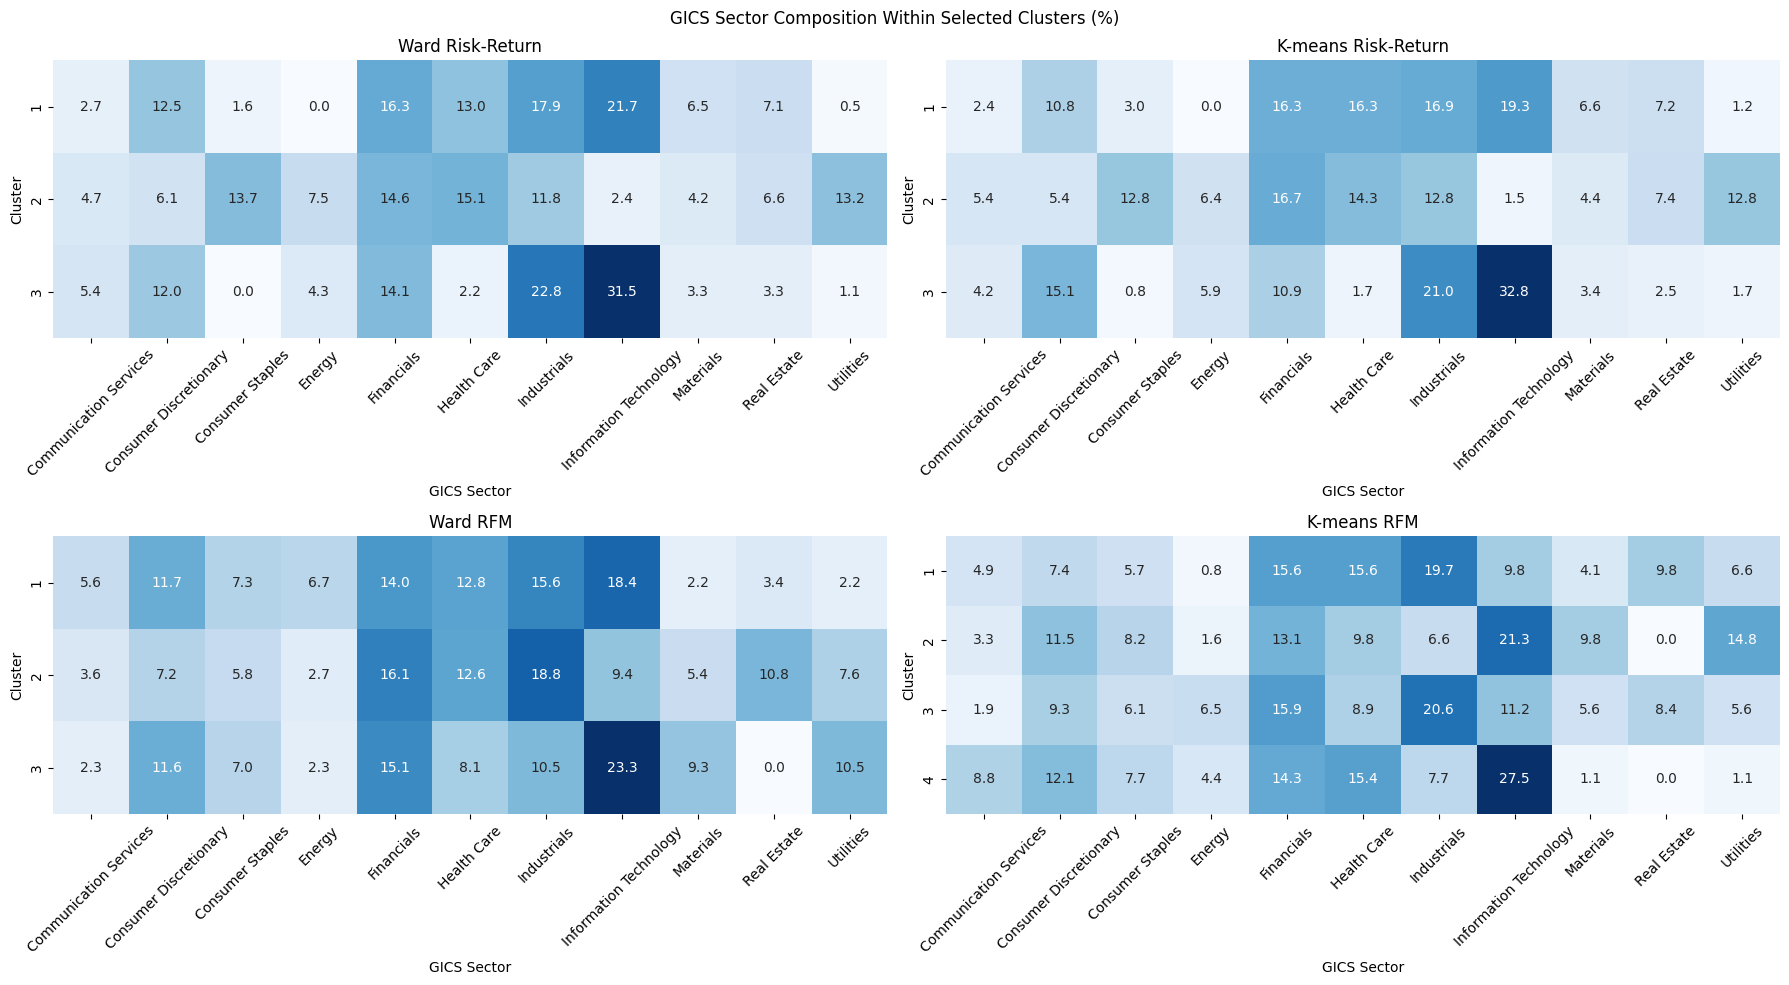

In [46]:
# Compare sector composition across the four selected clustering solutions.

import matplotlib.pyplot as plt
import seaborn as sns

sector_comparisons = {
    "Ward Risk-Return": "Ward_Risk_Cluster",
    "K-means Risk-Return": "KMeans_Risk_Cluster",
    "Ward RFM": "Ward_RFM_Cluster",
    "K-means RFM": "KMeans_RFM_Cluster"
}

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

for ax, (name, cluster_col) in zip(axes.flat, sector_comparisons.items()):

    sector_counts = pd.crosstab(
        task2_results[cluster_col],
        task2_results["GICS Sector"]
    )

    sector_pct = sector_counts.div(
        sector_counts.sum(axis=1), axis=0
    ) * 100

    sns.heatmap(
        sector_pct,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(name)
    ax.set_xlabel("GICS Sector")
    ax.set_ylabel("Cluster")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("GICS Sector Composition Within Selected Clusters (%)")
plt.tight_layout()
plt.show()

In [47]:
# Overall sector composition of the 488 retained shares.

sector_baseline = (
    task2_results["GICS Sector"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=False)
)

display(
    sector_baseline.rename("Overall Sample (%)")
    .round(1)
    .to_frame()
)

,Overall Sample (%)
GICS Sector,
Industrials,16.2
Information Technology,15.2
Financials,15.2
Health Care,11.9
Consumer Discretionary,9.6
Consumer Staples,6.6
Utilities,6.1
Real Estate,6.1
Materials,4.9


In [48]:
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Compare different feature sets, using the same clustering algorithm.
comparisons = {
    "Ward: Risk-Return vs RFM":
        ("Ward_Risk_Cluster", "Ward_RFM_Cluster"),
    "K-means: Risk-Return vs RFM":
        ("KMeans_Risk_Cluster", "KMeans_RFM_Cluster")
}

for name, (risk_col, rfm_col) in comparisons.items():
    print(f"\n{name}")

    display(pd.crosstab(
        task2_results[risk_col],
        task2_results[rfm_col]
    ))

    ari = adjusted_rand_score(
        task2_results[risk_col],
        task2_results[rfm_col]
    )

    print(f"Adjusted Rand Index: {ari:.3f}")


Ward: Risk-Return vs RFM


Ward_RFM_Cluster,1,2,3
Ward_Risk_Cluster,,,
1,61,90,33
2,76,103,33
3,42,30,20


Adjusted Rand Index: 0.010

K-means: Risk-Return vs RFM


KMeans_RFM_Cluster,1,2,3,4
KMeans_Risk_Cluster,,,,
1,43,20,80,23
2,53,23,93,34
3,26,18,41,34


Adjusted Rand Index: 0.012


In [49]:
# Compare the typical share in each selected cluster.
risk_solutions = {
    "Ward Risk-Return": "Ward_Risk_Cluster",
    "K-means Risk-Return": "KMeans_Risk_Cluster"
}

rfm_solutions = {
    "Ward RFM": "Ward_RFM_Cluster",
    "K-means RFM": "KMeans_RFM_Cluster"
}

for name, cluster_col in risk_solutions.items():
    profiles = task2_results.groupby(cluster_col).agg(
        Shares=("Mean_Weekly_Return", "size"),
        Median_Weekly_Return=("Mean_Weekly_Return", "median"),
        Median_Beta=("Weekly_Beta", "median")
    )

    profiles["Median_Weekly_Return"] *= 100

    print(f"\n{name} — Return in % per week")
    display(profiles.round(3))


for name, cluster_col in rfm_solutions.items():
    profiles = task2_results.groupby(cluster_col).agg(
        Shares=("Recency_Days", "size"),
        Median_Recency=("Recency_Days", "median"),
        Median_Frequency=("Frequency_60", "median"),
        Median_Monetary=("Monetary_60_USD", "median")
    )

    profiles["Median_Monetary"] /= 1e9

    print(f"\n{name} — Monetary in US$ billions")
    display(profiles.round(3))


Ward Risk-Return — Return in % per week


,Shares,Median_Weekly_Return,Median_Beta
Ward_Risk_Cluster,,,
1,184,0.180,1.089
2,212,0.251,0.632
3,92,0.550,1.218



K-means Risk-Return — Return in % per week


,Shares,Median_Weekly_Return,Median_Beta
KMeans_Risk_Cluster,,,
1,166,0.118,1.081
2,203,0.259,0.622
3,119,0.528,1.221



Ward RFM — Monetary in US$ billions


,Shares,Median_Recency,Median_Frequency,Median_Monetary
Ward_RFM_Cluster,,,,
1,179,11.0,3.0,34.321
2,223,11.0,3.0,10.140
3,86,54.0,2.0,21.450



K-means RFM — Monetary in US$ billions


,Shares,Median_Recency,Median_Frequency,Median_Monetary
KMeans_RFM_Cluster,,,,
1,122,11.0,4.0,12.826
2,61,55.0,2.0,21.242
3,214,11.0,2.0,13.336
4,91,11.0,3.0,60.183


In [50]:
import numpy as np
from scipy.stats import chi2_contingency

# Measure descriptive association between sectors and clusters.
sector_results = []

for name, cluster_col in sector_comparisons.items():

    counts = pd.crosstab(
        task2_results[cluster_col],
        task2_results["GICS Sector"]
    )

    chi2, p_value, dof, expected = chi2_contingency(counts)

    n = counts.to_numpy().sum()
    cramers_v = np.sqrt(
        chi2 / (n * min(counts.shape[0] - 1, counts.shape[1] - 1))
    )

    sector_results.append({
        "Solution": name,
        "Cramers_V": cramers_v,
        "Cells_Expected_Below_5": (expected < 5).sum(),
        "Total_Cells": expected.size
    })

sector_association = pd.DataFrame(sector_results)

display(sector_association.round(3))

,Solution,Cramers_V,Cells_Expected_Below_5,Total_Cells
0,Ward Risk-Return,0.382,3,33
1,K-means Risk-Return,0.381,2,33
2,Ward RFM,0.232,3,33
3,K-means RFM,0.232,9,44


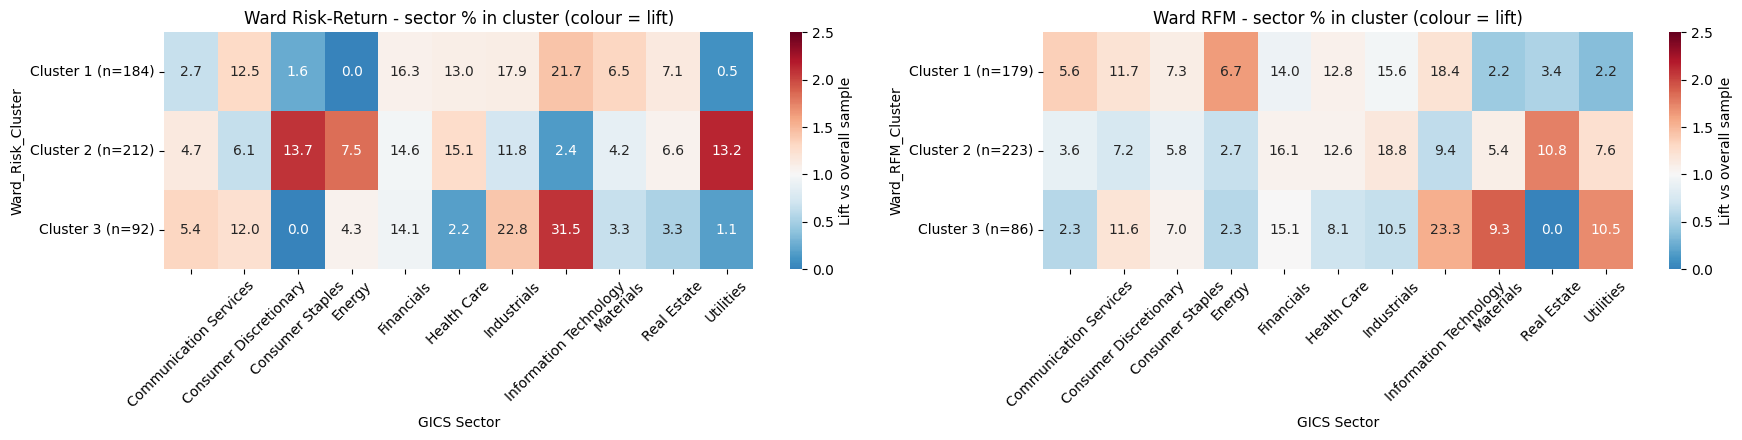

,Shares,Median_Weekly_Return_pct,Median_Beta
Ward_Risk_Cluster,,,
1,184,0.180,1.089
2,212,0.251,0.632
3,92,0.550,1.218


,Shares,Median_Recency,Median_Frequency,Median_Monetary_USD_bn
Ward_RFM_Cluster,,,,
1,179,11.0,3.0,34.32
2,223,11.0,3.0,10.14
3,86,54.0,2.0,21.45


In [51]:
baseline = task2_results["GICS Sector"].value_counts(normalize=True)
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
for ax, (name, col) in zip(axes, {"Ward Risk-Return": "Ward_Risk_Cluster", "Ward RFM": "Ward_RFM_Cluster"}.items()):
    counts = pd.crosstab(task2_results[col], task2_results["GICS Sector"])
    pct = counts.div(counts.sum(axis=1), axis=0)
    lift = pct.div(baseline[pct.columns], axis=1)
    sns.heatmap(lift, annot=pct.mul(100).round(1), fmt="", cmap="RdBu_r", center=1, vmin=0, vmax=2.5,
                ax=ax, cbar_kws={"label": "Lift vs overall sample"})
    ax.set_yticklabels([f"Cluster {c} (n={counts.loc[c].sum()})" for c in lift.index], rotation=0)
    ax.set_title(name + " - sector % in cluster (colour = lift)")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

risk_profile = task2_results.groupby("Ward_Risk_Cluster").agg(
    Shares=("Weekly_Beta", "size"),
    Median_Weekly_Return_pct=("Mean_Weekly_Return", lambda s: s.median() * 100),
    Median_Beta=("Weekly_Beta", "median")).round(3)
rfm_profile = task2_results.groupby("Ward_RFM_Cluster").agg(
    Shares=("Recency_Days", "size"), Median_Recency=("Recency_Days", "median"),
    Median_Frequency=("Frequency_60", "median"),
    Median_Monetary_USD_bn=("Monetary_60_USD", lambda s: s.median() / 1e9)).round(2)
display(risk_profile); display(rfm_profile)

In [54]:
kept = feature_table.index.tolist()
corr = share_weekly_returns[kept].corr()

def avg_pair_corr(tickers):
    c = corr.loc[tickers, tickers].values
    return (c.sum() - len(tickers)) / (len(tickers) * (len(tickers) - 1))

rows = [{"Grouping": "All shares", "Cluster": "-", "Shares": len(kept), "Avg_pairwise_corr": avg_pair_corr(kept)}]
for col in ["Ward_Risk_Cluster", "Ward_RFM_Cluster"]:
    for c, grp in task2_results.groupby(col):
        rows.append({"Grouping": col, "Cluster": c, "Shares": len(grp), "Avg_pairwise_corr": avg_pair_corr(grp.index.tolist())})
for s, grp in task2_results.groupby("GICS Sector"):
    if len(grp) > 1:
        rows.append({"Grouping": "GICS sector", "Cluster": s, "Shares": len(grp), "Avg_pairwise_corr": avg_pair_corr(grp.index.tolist())})
display(pd.DataFrame(rows).round(3))

,Grouping,Cluster,Shares,Avg_pairwise_corr
0,All shares,-,488,0.299
1,Ward_Risk_Cluster,1,184,0.383
2,Ward_Risk_Cluster,2,212,0.287
3,Ward_Risk_Cluster,3,92,0.374
4,Ward_RFM_Cluster,1,179,0.292
5,Ward_RFM_Cluster,2,223,0.321
6,Ward_RFM_Cluster,3,86,0.277
7,GICS sector,Communication Services,20,0.275
8,GICS sector,Consumer Discretionary,47,0.363
9,GICS sector,Consumer Staples,32,0.331


In [55]:
close_weekly = (pd.DataFrame({t: shares_daily[t]["Close"] for t in kept})
                .loc[:str(pd.Timestamp(end) - pd.Timedelta(days=1))]
                .resample("W-FRI").last().reindex(aligned_prices.index))
close_mean = close_weekly.pct_change(fill_method=None).iloc[1:].mean()
diff = close_mean - mean_weekly_return[kept]
print("Mean difference (Close minus Adj Close), % per week:", round(diff.mean() * 100, 4))
print("Largest absolute difference, % per week:", round(diff.abs().max() * 100, 4))
print("Shares differing by more than 0.05 percentage points per week:", int((diff.abs() > 0.0005).sum()))
print("Rank correlation of mean return, Close vs Adj Close:",
      round(close_mean.rank().corr(mean_weekly_return[kept].rank()), 4))

Mean difference (Close minus Adj Close), % per week: -0.0348
Largest absolute difference, % per week: 0.1516
Shares differing by more than 0.05 percentage points per week: 140
Rank correlation of mean return, Close vs Adj Close: 0.9903


#### 3.2.3 — Critical Evaluation and Limitations

#### Return Dependencies

Beta measures sensitivity to the S&P 500 benchmark, but does not
show how shares move with each other.

compared average pairwise weekly-return correlations across all
488 shares, within Ward clusters and within GICS sectors to check
whether the groups also shared similar return movements.

#### Price Adjustment Sensitivity

I compared mean weekly returns calculated using Close and Adj Close
to examine how the price adjustment choice affects the results.

This is a return sensitivity check; beta was not recalculated
using Close prices.